# ARIMA Model Development

COMP8851 – AI-Powered Stock Market Prediction

## Objective

Creating a forecasting model using ARIMA for six stock prices: AAPL, NVDA, JPM, BHP, CBA, and GMG. The testing of the model will be done using the same quarterly intervals as the LSTM and CNN-LSTM models. We aim to forecast the closing price on the following day.

In [1]:
import pandas as pd

# Loading Apple's historical stock data
aapl = pd.read_csv("Dataset/AAPL_historical_data.csv")

# Checking the size of the dataset
print("Dataset shape:", aapl.shape)

# Checking the available columns
print("\nColumn names:")
print(aapl.columns.tolist())

# Displaying the first five observations
print("\nFirst 5 rows:")
display(aapl.head())

# Checking for missing values
print("\nMissing values:")
print(aapl.isnull().sum())

Dataset shape: (2010, 7)

Column names:
['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

First 5 rows:


,Date,Open,High,Low,Close,Adj Close,Volume
0,30 Dec 2025,272.81,274.08,272.28,273.08,272.34,22139600
1,29 Dec 2025,272.69,274.36,272.35,273.76,273.02,23715200
2,26 Dec 2025,274.16,275.37,272.86,273.40,272.66,21521800
3,24 Dec 2025,272.34,275.43,272.20,273.81,273.07,17910600
4,23 Dec 2025,270.84,272.50,269.56,272.36,271.62,29642000



Missing values:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


In [2]:

import numpy as np

# Preparing AAPL data for modeling
aapl_clean = aapl.copy()

aapl_clean["Date"] = pd.to_datetime(
    aapl_clean["Date"], format="%d %b %Y"
)

aapl_clean = aapl_clean.sort_values("Date")

# Removing non-trading observations, if any
non_trading = (
    (aapl_clean["Volume"] == 0) &
    (aapl_clean["High"] == aapl_clean["Low"])
)

aapl_clean = aapl_clean.loc[~non_trading].set_index("Date")

# Selecting Fold 1: January to March 2023
test_start = pd.Timestamp("2023-01-01")
test_end = pd.Timestamp("2023-03-31")

# Validation boundary:
feature_dates = aapl_clean.index[1:]
pre_test_dates = feature_dates[feature_dates < test_start]

val_start = pre_test_dates[int(len(pre_test_dates) * 0.85)]

# Separating the closing-price observations
train_close = aapl_clean.loc[
    aapl_clean.index < val_start, "Close"
]

val_close = aapl_clean.loc[
    (aapl_clean.index >= val_start) &
    (aapl_clean.index < test_start), "Close"
]

test_close = aapl_clean.loc[
    (aapl_clean.index >= test_start) &
    (aapl_clean.index <= test_end), "Close"
]

# Displaying results
print("Stock: AAPL")
print("Fold: 1")

print("\nTraining observations:", len(train_close))
print("Validation observations:", len(val_close))
print("Testing observations:", len(test_close))

print("\nValidation starts:", val_start.date())
print("First test date:", test_close.index.min().date())
print("Last test date:", test_close.index.max().date())


Stock: AAPL
Fold: 1

Training observations: 1070
Validation observations: 189
Testing observations: 62

Validation starts: 2022-04-01
First test date: 2023-01-03
Last test date: 2023-03-31


In [3]:

# Converting closing prices to natural logarithms

# Ensuring that all closing prices are positive
assert (train_close > 0).all()
assert (val_close > 0).all()
assert (test_close > 0).all()

# Applying log transformation
train_log = np.log(train_close)
val_log = np.log(val_close)
test_log = np.log(test_close)

# Displaying results
print("First 5 training log prices:")
display(train_log.head())

print("\nTraining observations:", len(train_log))
print("Validation observations:", len(val_log))
print("Testing observations:", len(test_log))

# Confirming that we can convert back to the original price
print("\nOriginal closing price:", train_close.iloc[0])
print("Recovered closing price:", np.exp(train_log.iloc[0]))


First 5 training log prices:


Date
2018-01-02    3.762594
2018-01-03    3.762594
2018-01-04    3.767228
2018-01-05    3.778492
2018-01-08    3.774828
Name: Close, dtype: float64


Training observations: 1070
Validation observations: 189
Testing observations: 62

Original closing price: 43.06
Recovered closing price: 43.06


## Initial ARIMA Model

We will fit an ARIMA(1,1,1) model using AAPL's training data from Fold 1. This will serve as an initial test before selecting the best ARIMA paramters using AIC values.

In [4]:
from statsmodels.tsa.arima.model import ARIMA

# Building an initial ARIMA(1,1,1) model
# Using training observations only
model = ARIMA(
    train_log.to_numpy(),
    order=(1, 1, 1)
)

# Training the model
model_fit = model.fit()

# Displaying the results
print("ARIMA(1,1,1) successfully fitted!")

print("\nAIC:", model_fit.aic)

print("\nModel summary:")
print(model_fit.summary())


ARIMA(1,1,1) successfully fitted!

AIC: -5268.3488943242155

Model summary:
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1070
Model:                 ARIMA(1, 1, 1)   Log Likelihood                2637.174
Date:                Tue, 03 Nov 2026   AIC                          -5268.349
Time:                        22:00:33   BIC                          -5253.425
Sample:                             0   HQIC                         -5262.695
                               - 1070                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2904      0.150     -1.935      0.053      -0.585       0.004
ma.L1          0.1761      0.157      1.123      0.261 

## Preliminary ARIMA Model Selection

We will compare different ARIMA configurations using AIC. All models are fitted using AAPL's Fold 1 training data only.

In [5]:
# Comparing initial ARIMA configurations using AIC

results = []

for p in range(2):
    for q in range(2):
        for drift in [False, True]:

            trend = "t" if drift else "n"

            try:
                candidate = ARIMA(
                    train_log.to_numpy(),
                    order=(p, 1, q),
                    trend=trend
                )

                fitted = candidate.fit()

                converged = fitted.mle_retvals.get(
                    "converged", False
                )

                results.append({
                    "p": p,
                    "d": 1,
                    "q": q,
                    "Drift": drift,
                    "AIC": fitted.aic,
                    "Converged": converged
                })

            except Exception as e:
                print(f"ARIMA({p},1,{q}) failed: {e}")

# Creating a comparison table
aic_results = pd.DataFrame(results)

aic_results = aic_results.sort_values(
    "AIC"
).reset_index(drop=True)

display(aic_results)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,p,d,q,Drift,AIC,Converged
0,1,1,0,True,-5273.370622,True
1,0,1,1,True,-5272.785794,True
2,1,1,1,True,-5271.639466,True
3,1,1,0,False,-5269.897848,True
4,0,1,1,False,-5269.212716,False
5,1,1,1,False,-5268.348894,True
6,0,1,0,True,-5259.576550,True
7,0,1,0,False,-5257.278802,True



## Full ARIMA Model Selection

We will now compare all 72 ARIMA configurations using AIC. Only models that converge successfully will be considered for the final selection.


In [6]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning

# Storing model comparison results
full_results = []

# Testing p and q from 0 to 5
for p in range(6):
    for q in range(6):
        for drift in [False, True]:

            trend = "t" if drift else "n"

            try:
                with warnings.catch_warnings():
                    warnings.simplefilter(
                        "ignore", ConvergenceWarning
                    )

                    model = ARIMA(
                        train_log.to_numpy(),
                        order=(p, 1, q),
                        trend=trend
                    )

                    fitted = model.fit()

                converged = fitted.mle_retvals.get(
                    "converged", False
                )

                full_results.append({
                    "p": p,
                    "d": 1,
                    "q": q,
                    "Drift": drift,
                    "AIC": fitted.aic,
                    "Converged": converged
                })

            except Exception as e:
                print(
                    f"ARIMA({p},1,{q}), drift={drift}: {e}"
                )

# Creating results table
full_aic_results = pd.DataFrame(full_results)

# Keeping successfully converged models only
valid_models = full_aic_results[
    (full_aic_results["Converged"]) &
    (np.isfinite(full_aic_results["AIC"]))
].copy()

# Sorting from lowest to highest AIC
valid_models = valid_models.sort_values(
    "AIC"
).reset_index(drop=True)

print("Total configurations attempted: 72")
print("Successful fits:", len(valid_models))

print("\nTop 10 ARIMA configurations:")
display(valid_models.head(10))

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros

Total configurations attempted: 72
Successful fits: 52

Top 10 ARIMA configurations:


,p,d,q,Drift,AIC,Converged
0,4,1,4,False,-5292.567476,True
1,1,1,5,True,-5274.970154,True
2,1,1,0,True,-5273.370622,True
3,0,1,1,True,-5272.785794,True
4,1,1,1,True,-5271.639466,True
5,2,1,0,True,-5271.579635,True
6,0,1,3,True,-5269.933974,True
7,1,1,0,False,-5269.897848,True
8,3,1,0,True,-5269.890241,True
9,2,1,1,True,-5269.549262,True



## ARIMA Model Diagnostics

Checking the leading AIC model for convergence, parameter stability and remaining autocorrelation in the residuals.


In [7]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Selecting the model with the lowest valid AIC
best = valid_models.iloc[0]

p = int(best["p"])
q = int(best["q"])
drift = bool(best["Drift"])

# Fitting the selected ARIMA model
best_model = ARIMA(
    train_log.to_numpy(),
    order=(p, 1, q),
    trend="t" if drift else "n"
)

best_fit = best_model.fit()

print(f"Selected model: ARIMA({p},1,{q})")
print("Drift:", drift)
print("AIC:", best_fit.aic)
print("Converged:", best_fit.mle_retvals.get("converged"))

# Checking AR and MA roots
print("\nMinimum absolute AR root:",
      np.min(np.abs(best_fit.arroots)))

print("Minimum absolute MA root:",
      np.min(np.abs(best_fit.maroots)))

# Removing the initialisation residual
residuals = best_fit.resid[1:]

# Ljung-Box test at lags 10 and 20
ljung_box = acorr_ljungbox(
    residuals,
    lags=[10, 20],
    return_df=True
)

print("\nLjung-Box test:")
display(ljung_box)

print("\nModel parameters:")
print(best_fit.params)


Selected model: ARIMA(4,1,4)
Drift: False
AIC: -5292.567475580872
Converged: True

Minimum absolute AR root: 1.0372910854370934
Minimum absolute MA root: 1.0786109510715687

Ljung-Box test:


,lb_stat,lb_pvalue
10,7.058851,0.719878
20,20.635692,0.418847



Model parameters:
[-9.95895150e-01 -3.93214160e-02 -2.28541202e-01 -5.02591444e-01
  9.14063524e-01 -4.13907810e-02  2.28800890e-01  4.63947486e-01
  4.07065589e-04]



## ARIMA Validation

We will now evaluate ARIMA(4,1,4) using AAPL's Fold 1 validation data. First we will forecast one trading day ahead, then update the model with the actual observation without re-estimating its parameters. Eventually we will compare ARIMA against the naive forecast using RMSE.


In [8]:

# One-day-ahead validation forecasting

validation_results = []

# Starting with the model trained on training data only
validation_state = best_fit

# The last known closing price before validation
last_actual_close = float(train_close.iloc[-1])

for date, actual_log in val_log.items():

    # Forecasting the next day's log closing price
    predicted_log = float(
        np.asarray(validation_state.forecast(steps=1))[0]
    )

    # Converting prediction back to closing price
    predicted_close = float(np.exp(predicted_log))
    actual_close = float(np.exp(actual_log))

    # Storing both ARIMA and naive predictions
    validation_results.append({
        "Date": date,
        "Actual_Close": actual_close,
        "ARIMA_Prediction": predicted_close,
        "Naive_Prediction": last_actual_close
    })

    # Updating with the real observation AFTER predicting
    validation_state = validation_state.append(
        [float(actual_log)],
        refit=False
    )

    last_actual_close = actual_close

# Creating results table
validation_df = pd.DataFrame(validation_results)

# Calculating RMSE for both forecasting approaches
arima_rmse = np.sqrt(np.mean(
    (validation_df["Actual_Close"] -
     validation_df["ARIMA_Prediction"]) ** 2
))

naive_rmse = np.sqrt(np.mean(
    (validation_df["Actual_Close"] -
     validation_df["Naive_Prediction"]) ** 2
))

print("Validation observations:", len(validation_df))

print("\nARIMA RMSE:", round(arima_rmse, 4))
print("Naive RMSE:", round(naive_rmse, 4))

print("\nFirst five validation predictions:")
display(validation_df.head())


Validation observations: 189

ARIMA RMSE: 3.476
Naive RMSE: 3.5019

First five validation predictions:


,Date,Actual_Close,ARIMA_Prediction,Naive_Prediction
0,2022-04-01,174.31,174.105080,174.61
1,2022-04-04,178.44,174.975498,174.31
2,2022-04-05,175.06,177.757659,178.44
3,2022-04-06,171.83,175.452828,175.06
4,2022-04-07,172.14,172.071502,171.83



## Final ARIMA Model for Fold 1

After validation, we will refit the selected ARIMA model using both training and validation observations. The January–March 2023 test data remains unseen during fitting.


In [9]:
# Combining training and validation log prices
pretest_log = pd.concat([train_log, val_log])

# Refitting the selected ARIMA model
final_model = ARIMA(
    pretest_log.to_numpy(),
    order=(p, 1, q),
    trend="t" if drift else "n"
)


# Refitting using the previous successful model's parameters. This allows more optimisation iterations

final_fit = final_model.fit(
    start_params=best_fit.params,
    method_kwargs={"maxiter": 1000}
)

# Displaying results
print(f"Final model: ARIMA({p},1,{q})")
print("Drift:", drift)

print("\nTraining + validation observations:", len(pretest_log))
print("Last observation used:", pretest_log.index.max().date())

print("\nAIC:", round(final_fit.aic, 4))
print("Converged:", final_fit.mle_retvals.get("converged"))

print("\nTest observations reserved:", len(test_log))


Final model: ARIMA(4,1,4)
Drift: False

Training + validation observations: 1259
Last observation used: 2022-12-30

AIC: -6170.1747
Converged: True

Test observations reserved: 62



## Final Model Diagnostics

Checking the refitted ARIMA model before forecasting the test quarter.


In [10]:

# Checking final model diagnostics

from statsmodels.stats.diagnostic import acorr_ljungbox

# Checking convergence
print("Converged:", final_fit.mle_retvals.get("converged"))

# Checking AR and MA roots
print("Minimum AR root:", np.min(np.abs(final_fit.arroots)))
print("Minimum MA root:", np.min(np.abs(final_fit.maroots)))

# Checking residual autocorrelation
final_residuals = np.asarray(final_fit.resid)[1:]

final_ljung_box = acorr_ljungbox(
    final_residuals,
    lags=[10, 20],
    model_df=p + q,
    return_df=True
)

print("\nFinal Ljung-Box test:")
display(final_ljung_box)


Converged: True
Minimum AR root: 1.0400727126311773
Minimum MA root: 1.0791858138360073

Final Ljung-Box test:


,lb_stat,lb_pvalue
10,5.683508,0.058323
20,17.687097,0.125527


## ARIMA Test Forecasting — AAPL Fold 1

We will be evaluating the final ARIMA(4,1,4) model on the first quarter of 2023. This will be done by generating one-day-ahead forecasts and updating the model with each actual observation without re-estimating the model parameters. Afwerwards, the ARIMA predictions will be compared with the naive forecase using RMSE.


In [11]:

# ARIMA forecasting on the test quarter

test_results = []

# Starting with the model fitted on training + validation
test_state = final_fit

# Last known closing price before testing
last_actual_close = float(pretest_log.pipe(np.exp).iloc[-1])

for date, actual_log in test_log.items():

    # Forecasting the next trading day's log closing price
    predicted_log = float(
        np.asarray(test_state.forecast(steps=1))[0]
    )

    # Converting log prediction to original closing price
    predicted_close = float(np.exp(predicted_log))
    actual_close = float(np.exp(actual_log))

    # Storing predictions
    test_results.append({
        "Date": date,
        "Actual_Close": actual_close,
        "ARIMA_Prediction": predicted_close,
        "Naive_Prediction": last_actual_close
    })

    # Adding the actual price only AFTER making the prediction
    # Keeping the fitted ARIMA parameters unchanged
    test_state = test_state.append(
        [float(actual_log)],
        refit=False
    )

    last_actual_close = actual_close

# Creating results table
test_df = pd.DataFrame(test_results)

# Calculating prediction errors
test_arima_rmse = np.sqrt(np.mean(
    (test_df["Actual_Close"] -
     test_df["ARIMA_Prediction"]) ** 2
))

test_naive_rmse = np.sqrt(np.mean(
    (test_df["Actual_Close"] -
     test_df["Naive_Prediction"]) ** 2
))

print("Stock: AAPL")
print("Fold: 1")
print("Test observations:", len(test_df))

print("\nARIMA Test RMSE:", round(test_arima_rmse, 4))
print("Naive Test RMSE:", round(test_naive_rmse, 4))

print("\nFirst five test predictions:")
display(test_df.head())

print("\nLast five test predictions:")
display(test_df.tail())


Stock: AAPL
Fold: 1
Test observations: 62

ARIMA Test RMSE: 2.3017
Naive Test RMSE: 2.2714

First five test predictions:


,Date,Actual_Close,ARIMA_Prediction,Naive_Prediction
0,2023-01-03,125.07,129.994284,129.93
1,2023-01-04,126.36,125.187896,125.07
2,2023-01-05,125.02,126.331152,126.36
3,2023-01-06,129.62,125.254731,125.02
4,2023-01-09,130.15,129.265293,129.62



Last five test predictions:


,Date,Actual_Close,ARIMA_Prediction,Naive_Prediction
57,2023-03-27,158.28,160.404075,160.25
58,2023-03-28,157.65,158.321445,158.28
59,2023-03-29,160.77,157.685897,157.65
60,2023-03-30,162.36,160.683688,160.77
61,2023-03-31,164.90,162.014049,162.36


## AAPL Fold 1 — Forecast Visualisation

Comparing actual closing prices against ARIMA and naive predictions during the first quarterly test period.

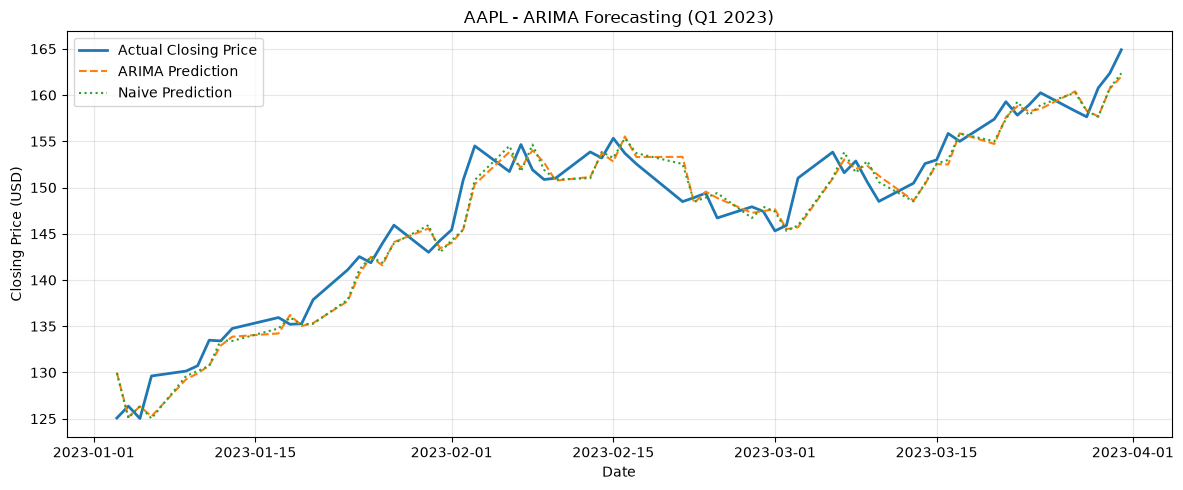

In [12]:
import matplotlib.pyplot as plt

# Plotting actual and predicted closing prices
plt.figure(figsize=(12, 5))

plt.plot(
    test_df["Date"],
    test_df["Actual_Close"],
    label="Actual Closing Price",
    linewidth=2
)

plt.plot(
    test_df["Date"],
    test_df["ARIMA_Prediction"],
    label="ARIMA Prediction",
    linestyle="--"
)

plt.plot(
    test_df["Date"],
    test_df["Naive_Prediction"],
    label="Naive Prediction",
    linestyle=":"
)

plt.title("AAPL - ARIMA Forecasting (Q1 2023)")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Saving ARIMA Results

Saving the predictions for AAPL Fold 1 so they can becompared with the LSTM and CNN-LSTM models later

In [13]:
from pathlib import Path

results_folder = Path("Results")
results_folder.mkdir(exist_ok=True)

# Results saved
aapl_fold1_results = test_df.copy()

aapl_fold1_results.insert(0, "Stock", "AAPL")
aapl_fold1_results.insert(1, "Fold", 1)

aapl_fold1_results["Model"] = "ARIMA(4,1,4)"
aapl_fold1_results["Outlier_Treatment"] = "Unclipped"

# Renaming columns for the group comparison
aapl_fold1_results = aapl_fold1_results.rename(
    columns={
        "ARIMA_Prediction": "Predicted_Close",
        "Naive_Prediction": "Previous_Close"
    }
)

# Saved as CSV
output_file = results_folder / "ARIMA_AAPL_Fold1_unclipped.csv"

aapl_fold1_results.to_csv(output_file, index=False)

print("Results saved successfully!")
print("File location:", output_file)

print("\nNumber of predictions:", len(aapl_fold1_results))

display(aapl_fold1_results.head())


Results saved successfully!
File location: Results/ARIMA_AAPL_Fold1_unclipped.csv

Number of predictions: 62


,Stock,Fold,Date,Actual_Close,Predicted_Close,Previous_Close,Model,Outlier_Treatment
0,AAPL,1,2023-01-03,125.07,129.994284,129.93,"ARIMA(4,1,4)",Unclipped
1,AAPL,1,2023-01-04,126.36,125.187896,125.07,"ARIMA(4,1,4)",Unclipped
2,AAPL,1,2023-01-05,125.02,126.331152,126.36,"ARIMA(4,1,4)",Unclipped
3,AAPL,1,2023-01-06,129.62,125.254731,125.02,"ARIMA(4,1,4)",Unclipped
4,AAPL,1,2023-01-09,130.15,129.265293,129.62,"ARIMA(4,1,4)",Unclipped


## Reusable Walk-Forward Data Preparation

Creating a function to prepare the training, validation and testing observations for different quarterly folds. The same procedure will be used for all six stocks.

In [14]:
def prepare_arima_fold(data, test_start, test_end):

    # Convert dates into timestamps
    test_start = pd.Timestamp(test_start)
    test_end = pd.Timestamp(test_end)

    # Using the same chronological validation approach
    feature_dates = data.index[1:]

    pre_test_dates = feature_dates[
        feature_dates < test_start
    ]

    # Last 15% of the historical period for validation
    val_start = pre_test_dates[
        int(len(pre_test_dates) * 0.85)
    ]

    # Separating training, validation and testing
    train = data.loc[
        data.index < val_start, "Close"
    ]

    validation = data.loc[
        (data.index >= val_start) &
        (data.index < test_start), "Close"
    ]

    test = data.loc[
        (data.index >= test_start) &
        (data.index <= test_end), "Close"
    ]

    # Ensuring all closing prices are positive
    assert (train > 0).all()
    assert (validation > 0).all()
    assert (test > 0).all()

    # Converting closing prices to log prices
    return {
        "train": np.log(train),
        "validation": np.log(validation),
        "test": np.log(test)
    }


# Testing the function on AAPL Fold 2
fold2 = prepare_arima_fold(
    aapl_clean,
    "2023-04-01",
    "2023-06-30"
)

print("AAPL - Fold 2")

print("Training observations:", len(fold2["train"]))
print("Validation observations:", len(fold2["validation"]))
print("Testing observations:", len(fold2["test"]))

print("\nFirst test date:", fold2["test"].index.min())
print("Last test date:", fold2["test"].index.max())

AAPL - Fold 2
Training observations: 1123
Validation observations: 198
Testing observations: 62

First test date: 2023-04-03 00:00:00
Last test date: 2023-06-30 00:00:00


## Reusable ARIMA Model Selection

This function will compare ARIMA configurations using AIC and retain models that converge successfully.

In [15]:
def select_arima_model(training_log, max_p=5, max_q=5):

    results = []

    for p in range(max_p + 1):
        for q in range(max_q + 1):
            for drift in [False, True]:

                try:
                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore")

                        model = ARIMA(
                            training_log.to_numpy(),
                            order=(p, 1, q),
                            trend="t" if drift else "n"
                        )

                        fitted = model.fit()

                    if (
                        fitted.mle_retvals.get("converged", False)
                        and np.isfinite(fitted.aic)
                    ):
                        results.append({
                            "p": p,
                            "d": 1,
                            "q": q,
                            "Drift": drift,
                            "AIC": fitted.aic
                        })

                except Exception:
                    continue

    results_df = pd.DataFrame(results)

    if results_df.empty:
        raise RuntimeError("No valid ARIMA models found.")

    return results_df.sort_values(
        "AIC"
    ).reset_index(drop=True)


print("ARIMA model-selection function created successfully!")


ARIMA model-selection function created successfully!



## AAPL Fold 2 — ARIMA Model Selection

Applying the reusable ARIMA model-selection function to Fold 2 and comparing ARIMA configurations using AIC on training data only.


In [16]:

# Selecting ARIMA models for AAPL Fold 2

fold2_results = select_arima_model(
    fold2["train"],
    max_p=5,
    max_q=5
)

print("Stock: AAPL")
print("Fold: 2")

print("\nSuccessfully fitted models:", len(fold2_results))

print("\nTop 10 ARIMA configurations:")
display(fold2_results.head(10))

# Identify the lowest-AIC candidate
best_fold2 = fold2_results.iloc[0]

print("\nLowest-AIC candidate:")
print(
    f"ARIMA({int(best_fold2['p'])},1,{int(best_fold2['q'])})"
)
print("Drift:", bool(best_fold2["Drift"]))
print("AIC:", round(best_fold2["AIC"], 4))


Stock: AAPL
Fold: 2

Successfully fitted models: 49

Top 10 ARIMA configurations:


,p,d,q,Drift,AIC
0,4,1,4,False,-5520.015408
1,1,1,5,True,-5502.596396
2,1,1,0,True,-5498.075008
3,0,1,1,True,-5497.669982
4,1,1,0,False,-5496.910061
5,0,1,1,False,-5496.435570
6,1,1,1,True,-5496.158219
7,2,1,0,True,-5496.135617
8,0,1,2,True,-5496.000033
9,1,1,1,False,-5495.062854



Lowest-AIC candidate:
ARIMA(4,1,4)
Drift: False
AIC: -5520.0154


## AAPL Fold 2 — Model Diagnostics

Checking the lowest-AIC ARIMA model for convergence, AR and MA roots, and residual autocorrelation.


In [17]:
# Selecting the lowest-AIC model for Fold 2
p2 = int(best_fold2["p"])
q2 = int(best_fold2["q"])
drift2 = bool(best_fold2["Drift"])

# Fitting the selected model using Fold 2 training data
fold2_model = ARIMA(
    fold2["train"].to_numpy(),
    order=(p2, 1, q2),
    trend="t" if drift2 else "n"
)

fold2_fit = fold2_model.fit()

# Checking convergence and roots
print(f"Selected model: ARIMA({p2},1,{q2})")
print("Drift:", drift2)
print("AIC:", round(fold2_fit.aic, 4))
print("Converged:", fold2_fit.mle_retvals.get("converged"))

print("\nMinimum AR root:",
      np.min(np.abs(fold2_fit.arroots)))

print("Minimum MA root:",
      np.min(np.abs(fold2_fit.maroots)))

# Checking residual autocorrelation
fold2_residuals = np.asarray(fold2_fit.resid)[1:]

fold2_ljungbox = acorr_ljungbox(
    fold2_residuals,
    lags=[10, 20],
    model_df=p2 + q2,
    return_df=True
)

print("\nLjung-Box test:")
display(fold2_ljungbox)


Selected model: ARIMA(4,1,4)
Drift: False
AIC: -5520.0154
Converged: True

Minimum AR root: 1.0482493587146118
Minimum MA root: 1.0999980893216545

Ljung-Box test:


,lb_stat,lb_pvalue
10,8.379582,0.015149
20,16.819630,0.156509



## AAPL Fold 2 — Alternative Model Diagnostics

The lowest-AIC model showed significant residual autocorrelation at lag 10, so we will investigate the second-best AIC candidate before
finalising the model selection.


In [18]:

# Selecting the second-best AIC model
alternative = fold2_results.iloc[1]

alt_p = int(alternative["p"])
alt_q = int(alternative["q"])
alt_drift = bool(alternative["Drift"])

# Fitting the alternative model
alternative_model = ARIMA(
    fold2["train"].to_numpy(),
    order=(alt_p, 1, alt_q),
    trend="t" if alt_drift else "n"
)

alternative_fit = alternative_model.fit(
    method_kwargs={"maxiter": 1000}
)

print(f"Alternative model: ARIMA({alt_p},1,{alt_q})")
print("Drift:", alt_drift)
print("AIC:", round(alternative_fit.aic, 4))
print("Converged:", alternative_fit.mle_retvals.get("converged"))

# Checking model roots
print("\nMinimum AR root:",
      np.min(np.abs(alternative_fit.arroots)))

print("Minimum MA root:",
      np.min(np.abs(alternative_fit.maroots)))

# Checking residual autocorrelation
alt_residuals = np.asarray(alternative_fit.resid)[1:]

alt_ljungbox = acorr_ljungbox(
    alt_residuals,
    lags=[10, 20],
    model_df=alt_p + alt_q,
    return_df=True
)

print("\nAlternative model Ljung-Box test:")
display(alt_ljungbox)


Alternative model: ARIMA(1,1,5)
Drift: True
AIC: -5502.5964
Converged: True

Minimum AR root: 1.1791281355506718
Minimum MA root: 1.0898203788341179

Alternative model Ljung-Box test:


,lb_stat,lb_pvalue
10,17.475694,0.001562
20,42.349834,0.000109



## AAPL Fold 2 — Validation

We will evaluate ARIMA(4,1,4) on the Fold 2 validation period and then compare one-day-ahead ARIMA predictions against the naive
forecast using RMSE. The test quarter will not be used during validation.


In [19]:

# AAPL Fold 2 validation

fold2_validation_results = []

# Using the model fitted on Fold 2 training data
validation_state = fold2_fit

# Last actual closing price before validation
last_actual_close = float(
    np.exp(fold2["train"].iloc[-1])
)

for date, actual_log in fold2["validation"].items():

    # Forecasting next day's log closing price
    predicted_log = float(
        np.asarray(validation_state.forecast(steps=1))[0]
    )

    predicted_close = float(np.exp(predicted_log))
    actual_close = float(np.exp(actual_log))

    fold2_validation_results.append({
        "Date": date,
        "Actual_Close": actual_close,
        "ARIMA_Prediction": predicted_close,
        "Naive_Prediction": last_actual_close
    })

    # Updating with the actual observation after forecasting
    validation_state = validation_state.append(
        [float(actual_log)],
        refit=False
    )

    last_actual_close = actual_close

# Creating results table
fold2_validation_df = pd.DataFrame(
    fold2_validation_results
)

# Calculating RMSE
fold2_arima_rmse = np.sqrt(np.mean(
    (fold2_validation_df["Actual_Close"] -
     fold2_validation_df["ARIMA_Prediction"]) ** 2
))

fold2_naive_rmse = np.sqrt(np.mean(
    (fold2_validation_df["Actual_Close"] -
     fold2_validation_df["Naive_Prediction"]) ** 2
))

print("AAPL - Fold 2 Validation")
print("Observations:", len(fold2_validation_df))

print("\nARIMA RMSE:", round(fold2_arima_rmse, 4))
print("Naive RMSE:", round(fold2_naive_rmse, 4))

print("\nFirst five validation predictions:")
display(fold2_validation_df.head())


AAPL - Fold 2 Validation
Observations: 198

ARIMA RMSE: 3.0023
Naive RMSE: 2.9883

First five validation predictions:


,Date,Actual_Close,ARIMA_Prediction,Naive_Prediction
0,2022-06-17,131.56,130.637810,130.06
1,2022-06-21,135.87,131.180642,131.56
2,2022-06-22,135.35,135.474161,135.87
3,2022-06-23,138.27,135.748755,135.35
4,2022-06-24,141.66,137.339764,138.27



## AAPL Fold 2 — Simpler Model Comparison

Comparing ARIMA(1,1,0) with drift against ARIMA(4,1,4) and the naive forecast.

In [20]:
# Fitting a simpler ARIMA(1,1,0) model with drift
simple_model = ARIMA(
    fold2["train"].to_numpy(),
    order=(1, 1, 0),
    trend="t"
)

simple_fit = simple_model.fit(
    method_kwargs={"maxiter": 1000}
)

print("Simple model converged:",
      simple_fit.mle_retvals.get("converged"))

# Forecasting the same validation period
simple_state = simple_fit
simple_predictions = []

for date, actual_log in fold2["validation"].items():

    predicted_log = float(
        np.asarray(simple_state.forecast(steps=1))[0]
    )

    simple_predictions.append(np.exp(predicted_log))

    # Updating AFTER predicting, without refitting
    simple_state = simple_state.append(
        [float(actual_log)],
        refit=False
    )

# Comparing accuracy
simple_rmse = np.sqrt(np.mean(
    (fold2_validation_df["Actual_Close"].to_numpy()
     - np.array(simple_predictions)) ** 2
))

print("\nFold 2 Validation RMSE:")
print("ARIMA(4,1,4):", round(fold2_arima_rmse, 4))
print("ARIMA(1,1,0):", round(simple_rmse, 4))
print("Naive:", round(fold2_naive_rmse, 4))


Simple model converged: True

Fold 2 Validation RMSE:
ARIMA(4,1,4): 3.0023
ARIMA(1,1,0): 2.994
Naive: 2.9883



## AAPL Fold 2 — Simpler Model Diagnostics

Checking whether ARIMA(1,1,0) with drift has significant residual autocorrelation at lags 10 and 20 and then comparing its diagnostics with ARIMA(4,1,4).


In [21]:

# Checking ARIMA(1,1,0) diagnostics

print("Model: ARIMA(1,1,0) with drift")
print("Converged:", simple_fit.mle_retvals.get("converged"))

# Checking AR root
print("\nMinimum AR root:",
      np.min(np.abs(simple_fit.arroots)))

# Checking residual autocorrelation
simple_residuals = np.asarray(simple_fit.resid)[1:]

simple_ljungbox = acorr_ljungbox(
    simple_residuals,
    lags=[10, 20],
    model_df=1,
    return_df=True
)

print("\nLjung-Box test:")
display(simple_ljungbox)


Model: ARIMA(1,1,0) with drift
Converged: True

Minimum AR root: 8.316914041699661

Ljung-Box test:


,lb_stat,lb_pvalue
10,40.246576,6.855363e-06
20,63.692282,9.943554e-07


## AAPL Fold 2 — Final Model Fitting

Refitting ARIMA(4,1,4) using both training and validation observations before the April–June 2023 test period. The test observations are excluded from model fitting.


In [22]:
# Combining Fold 2 training and validation observations
fold2_pretest = pd.concat([
    fold2["train"],
    fold2["validation"]
])

# Building the selected ARIMA(4,1,4) model
fold2_final_model = ARIMA(
    fold2_pretest.to_numpy(),
    order=(4, 1, 4),
    trend="n"
)

# Refitting using previously successful parameters
fold2_final_fit = fold2_final_model.fit(
    start_params=fold2_fit.params,
    method_kwargs={"maxiter": 1000}
)

# Eesults
print("Stock: AAPL")
print("Fold: 2")
print("Model: ARIMA(4,1,4)")

print("\nTraining + validation observations:",
      len(fold2_pretest))

print("Last observation used:",
      fold2_pretest.index.max().date())

print("\nAIC:", round(fold2_final_fit.aic, 4))
print("Converged:",
      fold2_final_fit.mle_retvals.get("converged"))

print("\nTest observations reserved:",
      len(fold2["test"]))


Stock: AAPL
Fold: 2
Model: ARIMA(4,1,4)

Training + validation observations: 1321
Last observation used: 2023-03-31

AIC: -6501.4017
Converged: True

Test observations reserved: 62


In [23]:
# Final diagnostics for AAPL Fold 2

print("Model: ARIMA(4,1,4)")
print("Converged:", fold2_final_fit.mle_retvals.get("converged"))

# Checking AR and MA roots
print("\nMinimum AR root:",
      np.min(np.abs(fold2_final_fit.arroots)))

print("Minimum MA root:",
      np.min(np.abs(fold2_final_fit.maroots)))

# Checking residual autocorrelation
fold2_final_residuals = np.asarray(
    fold2_final_fit.resid
)[1:]

fold2_final_ljungbox = acorr_ljungbox(
    fold2_final_residuals,
    lags=[10, 20],
    model_df=8,
    return_df=True
)

print("\nFinal Ljung-Box test:")
display(fold2_final_ljungbox)


Model: ARIMA(4,1,4)
Converged: True

Minimum AR root: 1.031177103436585
Minimum MA root: 1.0606673958526878

Final Ljung-Box test:


,lb_stat,lb_pvalue
10,5.866592,0.053221
20,18.476173,0.101979


## AAPL Fold 2 — Test Forecasting

Evaluating ARIMA(4,1,4) on the April–June 2023 test period. We will generate one-day-ahead forecasts using information available
up to the previous trading day and then compare ARIMA against the naive forecast using RMSE.


In [24]:
# AAPL Fold 2 test forecasting

fold2_test_results = []

# Starting with the final model fitted on training + validation
fold2_test_state = fold2_final_fit

# Last actual closing price before the test quarter
last_actual_close = float(np.exp(fold2_pretest.iloc[-1]))

for date, actual_log in fold2["test"].items():

    # Predicting the next day's log closing price
    predicted_log = float(
        np.asarray(fold2_test_state.forecast(steps=1))[0]
    )

    # Converting log predictions back to prices
    predicted_close = float(np.exp(predicted_log))
    actual_close = float(np.exp(actual_log))

    # Storing results
    fold2_test_results.append({
        "Date": date,
        "Actual_Close": actual_close,
        "ARIMA_Prediction": predicted_close,
        "Naive_Prediction": last_actual_close
    })

    # Updating the model with the real observation after making the prediction
    fold2_test_state = fold2_test_state.append(
        [float(actual_log)],
        refit=False
    )

    last_actual_close = actual_close

# Converting results into a DataFrame
fold2_test_df = pd.DataFrame(fold2_test_results)

# Calculating ARIMA RMSE
fold2_test_arima_rmse = np.sqrt(np.mean(
    (fold2_test_df["Actual_Close"] -
     fold2_test_df["ARIMA_Prediction"]) ** 2
))

# Calculating naive forecast RMSE
fold2_test_naive_rmse = np.sqrt(np.mean(
    (fold2_test_df["Actual_Close"] -
     fold2_test_df["Naive_Prediction"]) ** 2
))

print("Stock: AAPL")
print("Fold: 2")
print("Test observations:", len(fold2_test_df))

print("\nARIMA Test RMSE:", round(fold2_test_arima_rmse, 4))
print("Naive Test RMSE:", round(fold2_test_naive_rmse, 4))

print("\nFirst five predictions:")
display(fold2_test_df.head())

print("\nLast five predictions:")
display(fold2_test_df.tail())


Stock: AAPL
Fold: 2
Test observations: 62

ARIMA Test RMSE: 2.0289
Naive Test RMSE: 2.012

First five predictions:


,Date,Actual_Close,ARIMA_Prediction,Naive_Prediction
0,2023-04-03,166.17,164.878791,164.90
1,2023-04-04,165.63,165.666223,166.17
2,2023-04-05,163.76,166.033008,165.63
3,2023-04-06,164.66,163.670956,163.76
4,2023-04-10,162.03,165.011803,164.66



Last five predictions:


,Date,Actual_Close,ARIMA_Prediction,Naive_Prediction
57,2023-06-26,185.27,186.816593,186.68
58,2023-06-27,188.06,185.311976,185.27
59,2023-06-28,189.25,187.750355,188.06
60,2023-06-29,189.59,189.455918,189.25
61,2023-06-30,193.97,189.168888,189.59


In [25]:

# Preparing Fold 2 results for saving
aapl_fold2_results = fold2_test_df.copy()

aapl_fold2_results.insert(0, "Stock", "AAPL")
aapl_fold2_results.insert(1, "Fold", 2)

aapl_fold2_results = aapl_fold2_results.rename(
    columns={
        "ARIMA_Prediction": "Predicted_Close",
        "Naive_Prediction": "Previous_Close"
    }
)

# Adding model information
aapl_fold2_results["Model"] = "ARIMA(4,1,4)"
aapl_fold2_results["Outlier_Treatment"] = "Unclipped"

output_file = results_folder / "ARIMA_AAPL_Fold2_unclipped.csv"

aapl_fold2_results.to_csv(output_file, index=False)

print("Fold 2 results saved successfully!")
print("File location:", output_file)
print("Number of predictions:", len(aapl_fold2_results))

display(aapl_fold2_results.head())


Fold 2 results saved successfully!
File location: Results/ARIMA_AAPL_Fold2_unclipped.csv
Number of predictions: 62


,Stock,Fold,Date,Actual_Close,Predicted_Close,Previous_Close,Model,Outlier_Treatment
0,AAPL,2,2023-04-03,166.17,164.878791,164.90,"ARIMA(4,1,4)",Unclipped
1,AAPL,2,2023-04-04,165.63,165.666223,166.17,"ARIMA(4,1,4)",Unclipped
2,AAPL,2,2023-04-05,163.76,166.033008,165.63,"ARIMA(4,1,4)",Unclipped
3,AAPL,2,2023-04-06,164.66,163.670956,163.76,"ARIMA(4,1,4)",Unclipped
4,AAPL,2,2023-04-10,162.03,165.011803,164.66,"ARIMA(4,1,4)",Unclipped


## Reusable ARIMA Forecasting Function

This function will generate one-day-ahead closing-price predictions using a fitted ARIMA model. The model is will be updated with each actual observation after forecasting, without re-estimating its parameters.

In [26]:
def forecast_arima(fitted_model, test_log, previous_close):

    predictions = []

    # Fitted ARIMA model
    current_model = fitted_model
    last_close = float(previous_close)

    for date, actual_log in test_log.items():

        # Predicting the next trading day's log closing price
        predicted_log = float(
            np.asarray(current_model.forecast(steps=1))[0]
        )

        # Converting back to original closing prices
        predicted_close = float(np.exp(predicted_log))
        actual_close = float(np.exp(actual_log))

        # Saving predictions
        predictions.append({
            "Date": date,
            "Actual_Close": actual_close,
            "ARIMA_Prediction": predicted_close,
            "Naive_Prediction": last_close
        })

        # Updating with actual observation after forecasting
        current_model = current_model.append(
            [float(actual_log)],
            refit=False
        )

        last_close = actual_close

    results = pd.DataFrame(predictions)

    # Calculating forecasting accuracy
    arima_rmse = np.sqrt(np.mean(
        (results["Actual_Close"] -
         results["ARIMA_Prediction"]) ** 2
    ))

    naive_rmse = np.sqrt(np.mean(
        (results["Actual_Close"] -
         results["Naive_Prediction"]) ** 2
    ))

    return results, arima_rmse, naive_rmse

In [27]:

# Testing the reusable function on AAPL Fold 2

new_results, new_arima_rmse, new_naive_rmse = forecast_arima(
    fitted_model=fold2_final_fit,
    test_log=fold2["test"],
    previous_close=np.exp(fold2_pretest.iloc[-1])
)

print("AAPL - Fold 2")
print("Test observations:", len(new_results))

print("\nOriginal ARIMA RMSE:", round(fold2_test_arima_rmse, 4))
print("Function ARIMA RMSE:", round(new_arima_rmse, 4))

print("\nOriginal Naive RMSE:", round(fold2_test_naive_rmse, 4))
print("Function Naive RMSE:", round(new_naive_rmse, 4))

# Checking whether the results match
arima_match = np.isclose(
    fold2_test_arima_rmse,
    new_arima_rmse
)

naive_match = np.isclose(
    fold2_test_naive_rmse,
    new_naive_rmse
)

predictions_match = np.allclose(
    fold2_test_df["ARIMA_Prediction"].to_numpy(),
    new_results["ARIMA_Prediction"].to_numpy()
)

print("\nARIMA RMSE matches:", arima_match)
print("Naive RMSE matches:", naive_match)
print("Individual predictions match:", predictions_match)

print("\nFirst five predictions:")
display(new_results.head())


AAPL - Fold 2
Test observations: 62

Original ARIMA RMSE: 2.0289
Function ARIMA RMSE: 2.0289

Original Naive RMSE: 2.012
Function Naive RMSE: 2.012

ARIMA RMSE matches: True
Naive RMSE matches: True
Individual predictions match: True

First five predictions:


,Date,Actual_Close,ARIMA_Prediction,Naive_Prediction
0,2023-04-03,166.17,164.878791,164.90
1,2023-04-04,165.63,165.666223,166.17
2,2023-04-05,163.76,166.033008,165.63
3,2023-04-06,164.66,163.670956,163.76
4,2023-04-10,162.03,165.011803,164.66


In [28]:
def refit_arima(training_log, validation_log,
                initial_fit, p, q, drift):

    # Combining training and validation observations
    pretest_log = pd.concat([
        training_log,
        validation_log
    ])

    # Ensuring observations are in chronological order
    assert pretest_log.index.is_monotonic_increasing

    # Creating the selected ARIMA model
    model = ARIMA(
        pretest_log.to_numpy(),
        order=(p, 1, q),
        trend="t" if drift else "n"
    )

    # Refitting using previously successful parameters
    fitted = model.fit(
        start_params=initial_fit.params,
        method_kwargs={"maxiter": 1000}
    )

    # Checking convergence
    if not fitted.mle_retvals.get("converged", False):
        raise RuntimeError(
            f"ARIMA({p},1,{q}) failed to converge."
        )

    return fitted, pretest_log

In [29]:
# Testing reusable refitting function on Fold 2

check_fit, check_pretest = refit_arima(
    training_log=fold2["train"],
    validation_log=fold2["validation"],
    initial_fit=fold2_fit,
    p=4,
    q=4,
    drift=False
)

print("Converged:", check_fit.mle_retvals["converged"])
print("Observations:", len(check_pretest))
print("AIC:", round(check_fit.aic, 4))

print("\nMatches previous refit:",
      np.isclose(check_fit.aic, fold2_final_fit.aic))


Converged: True
Observations: 1321
AIC: -6501.4017

Matches previous refit: True


In [30]:
# Reusable function for ARIMA model diagnostics

def diagnose_arima(fitted_model, p, q):

    # Checking whether the model converged
    converged = fitted_model.mle_retvals.get(
        "converged", False
    )

    # Checking AR and MA roots
    ar_roots = np.abs(fitted_model.arroots)
    ma_roots = np.abs(fitted_model.maroots)

    min_ar_root = (
        float(np.min(ar_roots)) if len(ar_roots) else np.nan
    )

    min_ma_root = (
        float(np.min(ma_roots)) if len(ma_roots) else np.nan
    )

    # Calculate Ljung-Box statistics
    residuals = np.asarray(fitted_model.resid)[1:]

    ljungbox = acorr_ljungbox(
        residuals,
        lags=[10, 20],
        model_df=p + q,
        return_df=True
    )

    # Storing diagnostic results
    diagnostics = {
        "Converged": converged,
        "Min_AR_Root": min_ar_root,
        "Min_MA_Root": min_ma_root,
        "LjungBox_p10": ljungbox.loc[10, "lb_pvalue"],
        "LjungBox_p20": ljungbox.loc[20, "lb_pvalue"]
    }

    return diagnostics

In [31]:
# Testing the reusable diagnostics function

fold2_diagnostics = diagnose_arima(
    fitted_model=fold2_final_fit,
    p=4,
    q=4
)

print("AAPL Fold 2 - Final Model Diagnostics")

for key, value in fold2_diagnostics.items():
    print(f"{key}: {value}")


AAPL Fold 2 - Final Model Diagnostics
Converged: True
Min_AR_Root: 1.031177103436585
Min_MA_Root: 1.0606673958526878
LjungBox_p10: 0.053221321766280104
LjungBox_p20: 0.10197861939515275


In [32]:
# Reusing our forecasting function for Fold 2 validation

validation_check, validation_arima_rmse, validation_naive_rmse = forecast_arima(
    fitted_model=fold2_fit,
    test_log=fold2["validation"],
    previous_close=np.exp(fold2["train"].iloc[-1])
)

print("AAPL Fold 2 - Validation")

print("\nOriginal ARIMA RMSE:", round(fold2_arima_rmse, 4))
print("Function ARIMA RMSE:", round(validation_arima_rmse, 4))

print("\nOriginal Naive RMSE:", round(fold2_naive_rmse, 4))
print("Function Naive RMSE:", round(validation_naive_rmse, 4))

print("\nARIMA results match:",
      np.isclose(fold2_arima_rmse, validation_arima_rmse))

print("Naive results match:",
      np.isclose(fold2_naive_rmse, validation_naive_rmse))


AAPL Fold 2 - Validation

Original ARIMA RMSE: 3.0023
Function ARIMA RMSE: 3.0023

Original Naive RMSE: 2.9883
Function Naive RMSE: 2.9883

ARIMA results match: True
Naive results match: True


## ARIMA Model Selection — Simpler Model Rule

When multiple ARIMA models have AIC values within 2 points of the lowest AIC, this code will prefer the model with fewer parameters.

In [33]:
# Choosing the best ARIMA candidate using the AIC tie rule

def choose_arima_candidate(results_df):

    # Finding the lowest AIC
    lowest_aic = results_df["AIC"].min()

    # Keeping models within 2 AIC points
    close_models = results_df[
        results_df["AIC"] <= lowest_aic + 2
    ].copy()

    # Measuring model complexity
    close_models["Complexity"] = (
        close_models["p"] +
        close_models["q"] +
        close_models["Drift"].astype(int)
    )

    # Prefer simpler models, then lower AIC
    close_models = close_models.sort_values(
        ["Complexity", "AIC"]
    )

    return close_models.iloc[0]


# Testing using AAPL Fold 2
chosen = choose_arima_candidate(fold2_results)

print("Selected ARIMA model:")
print(
    f"ARIMA({int(chosen['p'])},1,{int(chosen['q'])})"
)

print("Drift:", bool(chosen["Drift"]))
print("AIC:", round(chosen["AIC"], 4))
print("Complexity:", int(chosen["Complexity"]))


Selected ARIMA model:
ARIMA(4,1,4)
Drift: False
AIC: -5520.0154
Complexity: 8


## Automated ARIMA Pipeline

Combining the existing functions for model selection, diagnostics, validation, refitting and test forecasting. Before that we must verify the pipeline using AAPL Fold 2.

In [34]:
def run_arima_fold(fold_data, model_results):

    # Selecting the best ARIMA configuration
    selected = choose_arima_candidate(model_results)

    p = int(selected["p"])
    q = int(selected["q"])
    drift = bool(selected["Drift"])

    print(f"Selected model: ARIMA({p},1,{q})")
    print("Drift:", drift)

    # Fitting the selected model on training data
    model = ARIMA(
        fold_data["train"].to_numpy(),
        order=(p, 1, q),
        trend="t" if drift else "n"
    )

    initial_fit = model.fit()

    if not initial_fit.mle_retvals.get("converged", False):
        raise RuntimeError("Initial model did not converge.")

    # Checking training diagnostics
    train_diagnostics = diagnose_arima(
        initial_fit, p, q
    )

    # Forecasting the validation period
    validation_results, val_arima_rmse, val_naive_rmse = forecast_arima(
        initial_fit,
        fold_data["validation"],
        np.exp(fold_data["train"].iloc[-1])
    )

    # Refitting using training + validation
    final_fit, pretest_log = refit_arima(
        fold_data["train"],
        fold_data["validation"],
        initial_fit,
        p, q, drift
    )

    # Checking final diagnostics
    final_diagnostics = diagnose_arima(
        final_fit, p, q
    )

    # Forecastings the test quarter
    test_results, test_arima_rmse, test_naive_rmse = forecast_arima(
        final_fit,
        fold_data["test"],
        np.exp(pretest_log.iloc[-1])
    )

    return {
        "Model": f"ARIMA({p},1,{q})",
        "Drift": drift,
        "Validation_ARIMA_RMSE": val_arima_rmse,
        "Validation_Naive_RMSE": val_naive_rmse,
        "Test_ARIMA_RMSE": test_arima_rmse,
        "Test_Naive_RMSE": test_naive_rmse,
        "Train_Diagnostics": train_diagnostics,
        "Final_Diagnostics": final_diagnostics,
        "Predictions": test_results
    }


print("Automated ARIMA pipeline created successfully!")


Automated ARIMA pipeline created successfully!


In [35]:
# Testing automated pipeline on AAPL Fold 2

pipeline_fold2 = run_arima_fold(
    fold_data=fold2,
    model_results=fold2_results
)

print("\nAAPL Fold 2 - Pipeline Results")

print("Model:", pipeline_fold2["Model"])

print(
    "Validation ARIMA RMSE:",
    round(pipeline_fold2["Validation_ARIMA_RMSE"], 4)
)

print(
    "Test ARIMA RMSE:",
    round(pipeline_fold2["Test_ARIMA_RMSE"], 4)
)

print(
    "Test Naive RMSE:",
    round(pipeline_fold2["Test_Naive_RMSE"], 4)
)

print(
    "\nTest predictions:",
    len(pipeline_fold2["Predictions"])
)


Selected model: ARIMA(4,1,4)
Drift: False

AAPL Fold 2 - Pipeline Results
Model: ARIMA(4,1,4)
Validation ARIMA RMSE: 3.0023
Test ARIMA RMSE: 2.0289
Test Naive RMSE: 2.012

Test predictions: 62


In [36]:

# Verifying all 12 quarterly folds for AAPL

fold_summary = []

quarter_starts = pd.date_range(
    start="2023-01-01",
    periods=12,
    freq="QS"
)

for fold_number, start in enumerate(quarter_starts, 1):

    end = start + pd.offsets.QuarterEnd(0)

    # Reusing our existing preparation function
    fold_data = prepare_arima_fold(
        aapl_clean,
        start,
        end
    )

    train = fold_data["train"]
    validation = fold_data["validation"]
    test = fold_data["test"]

    # Confirming chronological separation
    assert train.index.max() < validation.index.min()
    assert validation.index.max() < test.index.min()

    # Storing fold information
    fold_summary.append({
        "Fold": fold_number,
        "Test_Period": f"{start.year} Q{start.quarter}",
        "Training": len(train),
        "Validation": len(validation),
        "Testing": len(test),
        "First_Test_Date": test.index.min().date(),
        "Last_Test_Date": test.index.max().date()
    })

fold_summary_df = pd.DataFrame(fold_summary)

print("Total folds:", len(fold_summary_df))
print("\nQuarterly fold summary:")

display(fold_summary_df)


Total folds: 12

Quarterly fold summary:


,Fold,Test_Period,Training,Validation,Testing,First_Test_Date,Last_Test_Date
0,1,2023 Q1,1070,189,62,2023-01-03,2023-03-31
1,2,2023 Q2,1123,198,62,2023-04-03,2023-06-30
2,3,2023 Q3,1175,208,63,2023-07-03,2023-09-29
3,4,2023 Q4,1229,217,63,2023-10-02,2023-12-29
4,5,2024 Q1,1282,227,61,2024-01-02,2024-03-28
5,6,2024 Q2,1334,236,63,2024-04-01,2024-06-28
6,7,2024 Q3,1388,245,64,2024-07-01,2024-09-30
7,8,2024 Q4,1442,255,64,2024-10-01,2024-12-31
8,9,2025 Q1,1497,264,60,2025-01-02,2025-03-31
9,10,2025 Q2,1548,273,62,2025-04-01,2025-06-30


In [37]:
# Loading all six stocks for ARIMA

stock_files = {
    "AAPL": "AAPL_historical_data.csv",
    "NVDA": "NVDA_historical_data.csv",
    "JPM": "JPM_historical_data.csv",
    "BHP": "BHP.AX_historical_data.csv",
    "CBA": "CBA.AX_historical_data.csv",
    "GMG": "GMG.AX_historical_data.csv"
}

all_stocks = {}
stock_summary = []

for stock, filename in stock_files.items():

    # Loading the dataset
    data = pd.read_csv(f"Dataset/{filename}")

    # Converting and sorting dates
    data["Date"] = pd.to_datetime(
        data["Date"],
        format="%d %b %Y"
    )

    data = data.sort_values("Date")

    # Applying the same initial filtering as AAPL
    non_trading = (
        (data["Volume"] == 0) &
        (data["High"] == data["Low"])
    )

    data = data.loc[~non_trading].copy()

    # Checking for duplicate dates
    assert not data["Date"].duplicated().any()

    # Setting Date as index
    data = data.set_index("Date")

    # Checking closing prices
    assert data["Close"].notna().all()
    assert (data["Close"] > 0).all()

    # Storing prepared data
    all_stocks[stock] = data

    stock_summary.append({
        "Stock": stock,
        "Observations": len(data),
        "Start_Date": data.index.min().date(),
        "End_Date": data.index.max().date()
    })

# Creating a summary DataFrame for all stocks
stock_summary_df = pd.DataFrame(stock_summary)

print("Stocks prepared:", len(all_stocks))

display(stock_summary_df)


Stocks prepared: 6


,Stock,Observations,Start_Date,End_Date
0,AAPL,2010,2018-01-02,2025-12-30
1,NVDA,2010,2018-01-02,2025-12-30
2,JPM,2010,2018-01-02,2025-12-30
3,BHP,2024,2018-01-02,2025-12-30
4,CBA,2024,2018-01-02,2025-12-30
5,GMG,2023,2018-01-02,2025-12-30


In [38]:
# Checking excluded observations across all six stocks

for stock, filename in stock_files.items():

    raw_data = pd.read_csv(f"Dataset/{filename}")

    excluded = raw_data[
        (raw_data["Volume"] == 0) &
        (raw_data["High"] == raw_data["Low"])
    ]

    print(f"\n{stock}: {len(excluded)} excluded rows")

    if not excluded.empty:
        display(excluded)


AAPL: 0 excluded rows

NVDA: 0 excluded rows

JPM: 0 excluded rows

BHP: 0 excluded rows

CBA: 0 excluded rows

GMG: 1 excluded rows


,Date,Open,High,Low,Close,Adj Close,Volume
218,19 Feb 2025,35.98,35.98,35.98,35.98,35.48,0


In [39]:
# Verifying quarterly walk-forward data partitions

fold_checks = []

# Defining the 12 quarterly test periods (2023–2025)
quarters = pd.period_range(
    start="2023Q1",
    end="2025Q4",
    freq="Q"
)

# Verifying the data partitions for each stock and quarter
for stock, data in all_stocks.items():

    # Excluding the first observation to align with return-based feature construction
    feature_dates = data.index[1:]

    for fold_number, quarter in enumerate(quarters, 1):

        # Defining the quarterly testing boundaries
        test_start = quarter.start_time
        test_end = quarter.end_time

        # Identifying historical observations before testing
        pre_test_dates = feature_dates[
            feature_dates < test_start
        ]

        # Allocating the final 15% of historical observations to the validation partition
        expected_val_start = pre_test_dates[
            int(len(pre_test_dates) * 0.85)
        ]

        # Identifying observations within the test quarter
        expected_test_dates = feature_dates[
            (feature_dates >= test_start) &
            (feature_dates <= test_end)
        ]

        # Generating the ARIMA data partitions
        arima_fold = prepare_arima_fold(
            data, test_start, test_end
        )

        # Verifying the validation boundary
        validation_match = (
            arima_fold["validation"].index.min()
            == expected_val_start
        )

        # Verifying the testing dates
        test_match = (
            arima_fold["test"].index.equals(
                expected_test_dates
            )
        )

        # Recording verification results
        fold_checks.append({
            "Stock": stock,
            "Fold": fold_number,
            "Validation_Match": validation_match,
            "Test_Match": test_match
        })

# Summarising partition verification
fold_checks_df = pd.DataFrame(fold_checks)

print("Total stock-fold combinations:", len(fold_checks_df))

print(
    "Matching validation boundaries:",
    fold_checks_df["Validation_Match"].sum()
)

print(
    "Matching test periods:",
    fold_checks_df["Test_Match"].sum()
)

# Identifying any inconsistent partitions
mismatches = fold_checks_df[
    ~fold_checks_df["Validation_Match"] |
    ~fold_checks_df["Test_Match"]
]

if mismatches.empty:
    print("\nAll partitions satisfy the specified date rules.")
else:
    print("\nPartition inconsistencies detected:")
    display(mismatches)


Total stock-fold combinations: 72
Matching validation boundaries: 72
Matching test periods: 72

All partitions satisfy the specified date rules.


## Verification Against Reference Preprocessing Results

We will compare ARIMA historical and test observation counts against the reference preprocessing notebook for all
twelve quarterly folds.

In [40]:
# Referencing observation counts from the preprocessing results
reference_historical = [
    1259, 1321, 1383, 1446, 1509, 1570,
    1633, 1697, 1761, 1821, 1883, 1947
]

reference_test = [
    62, 62, 63, 63, 61, 63,
    64, 64, 60, 62, 64, 63
]

# Comparing with the ARIMA quarterly fold summary
comparison = fold_summary_df.copy()

comparison["Historical_Match"] = (
    comparison["Training"] + comparison["Validation"]
    == reference_historical
)

comparison["Test_Match"] = (
    comparison["Testing"] == reference_test
)

# Displaying verification results
print("Historical counts match:",
      comparison["Historical_Match"].sum(), "/12")

print("Test counts match:",
      comparison["Test_Match"].sum(), "/12")

display(comparison[
    ["Fold", "Test_Period", "Historical_Match", "Test_Match"]
])

assert comparison["Historical_Match"].all()
assert comparison["Test_Match"].all()

print("\nAAPL fold counts match the reference results.")


Historical counts match: 12 /12
Test counts match: 12 /12


,Fold,Test_Period,Historical_Match,Test_Match
0,1,2023 Q1,True,True
1,2,2023 Q2,True,True
2,3,2023 Q3,True,True
3,4,2023 Q4,True,True
4,5,2024 Q1,True,True
5,6,2024 Q2,True,True
6,7,2024 Q3,True,True
7,8,2024 Q4,True,True
8,9,2025 Q1,True,True
9,10,2025 Q2,True,True



AAPL fold counts match the reference results.


## Establish a backup mechanism to estimate ARIMA.

Models will be ranked using AIC criteria and the simplest one preferred. If a particular candidate fails to converge, the next available model is tried. Any model selection is based solely on training data, thus there is no leaking of information from validation/test sets.

In [41]:
def fit_arima_with_fallback(training_log, model_results):

    # Ranking candidates using AIC and model complexity
    candidates = model_results.copy()

    candidates["Complexity"] = (
        candidates["p"]
        + candidates["q"]
        + candidates["Drift"].astype(int)
    )

    # Prioritising simpler models within two AIC points
    best_aic = candidates["AIC"].min()

    close_models = candidates[
        candidates["AIC"] <= best_aic + 2
    ].sort_values(["Complexity", "AIC"])

    remaining_models = candidates[
        candidates["AIC"] > best_aic + 2
    ].sort_values("AIC")

    ranked_candidates = pd.concat([
        close_models,
        remaining_models
    ])

    failed_attempts = []

    # Attempting candidate models in priority order
    for _, candidate in ranked_candidates.iterrows():

        p = int(candidate["p"])
        q = int(candidate["q"])
        drift = bool(candidate["Drift"])

        try:
            model = ARIMA(
                training_log.to_numpy(),
                order=(p, 1, q),
                trend="t" if drift else "n"
            )

            # Allowing additional iterations for convergence
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                fitted = model.fit(
                    method_kwargs={"maxiter": 1000}
                )

            if fitted.mle_retvals.get("converged", False):
                print(f"Successfully fitted ARIMA({p},1,{q})")
                print("Drift:", drift)
                print("AIC:", round(fitted.aic, 4))

                return candidate, fitted

            failed_attempts.append(
                f"ARIMA({p},1,{q}): non-convergence"
            )

        except Exception as error:
            failed_attempts.append(
                f"ARIMA({p},1,{q}): {str(error)}"
            )

    # Stopping if no candidate can be fitted successfully
    raise RuntimeError(
        "All ARIMA candidates failed.\n"
        + "\n".join(failed_attempts)
    )

In [42]:
# Verifying the fallback procedure using AAPL Fold 2

selected_candidate, robust_fit = fit_arima_with_fallback(
    fold2["train"],
    fold2_results
)

print(
    "Converged:",
    robust_fit.mle_retvals.get("converged", False)
)

print(
    "Selected order:",
    (
        int(selected_candidate["p"]),
        1,
        int(selected_candidate["q"])
    )
)


Successfully fitted ARIMA(4,1,4)
Drift: False
AIC: -5520.0154
Converged: True
Selected order: (4, 1, 4)


## Automated ARIMA Pipeline with Convergence Handling

Integrate model selection, the way we deal with convergence, residual diagnostics, validation forecast, final estimation, and out-of-sample test into one repeatable pipeline. The parameters for the model are selected based on the training dataset. Final estimation is done based on the training and validation data prior to the test quarter.

In [43]:
def run_arima_fold_robust(fold_data, model_results):
    """
    Executes the complete ARIMA forecasting procedure
    for one stock and one quarterly fold.
    """

    # Selecting and estimating a converged training model
    selected, initial_fit = fit_arima_with_fallback(
        fold_data["train"],
        model_results
    )

    p = int(selected["p"])
    q = int(selected["q"])
    drift = bool(selected["Drift"])

    # Evaluating model diagnostics on training residuals
    train_diagnostics = diagnose_arima(
        initial_fit, p, q
    )

    # Generating sequential one-step-ahead validation forecasts
    validation_results, val_rmse, val_naive_rmse = forecast_arima(
        initial_fit,
        fold_data["validation"],
        np.exp(fold_data["train"].iloc[-1])
    )

    # Re-estimating the selected model using all pre-test data
    final_fit, pretest_log = refit_arima(
        fold_data["train"],
        fold_data["validation"],
        initial_fit,
        p, q, drift
    )

    # Rejecting an unsuccessful final estimation
    if not final_fit.mle_retvals.get("converged", False):
        raise RuntimeError(
            f"Final ARIMA({p},1,{q}) estimation did not converge."
        )

    # Evaluating diagnostics after final model estimation
    final_diagnostics = diagnose_arima(
        final_fit, p, q
    )

    # Generating sequential one-step-ahead test forecasts
    test_results, test_rmse, test_naive_rmse = forecast_arima(
        final_fit,
        fold_data["test"],
        np.exp(pretest_log.iloc[-1])
    )

    # Returning forecasts, performance metrics and diagnostics
    return {
        "Model": f"ARIMA({p},1,{q})",
        "Drift": drift,
        "Validation_ARIMA_RMSE": val_rmse,
        "Validation_Naive_RMSE": val_naive_rmse,
        "Test_ARIMA_RMSE": test_rmse,
        "Test_Naive_RMSE": test_naive_rmse,
        "Train_Diagnostics": train_diagnostics,
        "Final_Diagnostics": final_diagnostics,
        "Predictions": test_results
    }


print("Robust ARIMA pipeline created successfully.")


Robust ARIMA pipeline created successfully.


In [44]:
# Verifying the updated pipeline against the reference experiment

robust_fold2 = run_arima_fold_robust(
    fold2,
    fold2_results
)

print("\nModel:", robust_fold2["Model"])

print(
    "Validation RMSE:",
    round(robust_fold2["Validation_ARIMA_RMSE"], 4)
)

print(
    "Test RMSE:",
    round(robust_fold2["Test_ARIMA_RMSE"], 4)
)

print(
    "Naive RMSE:",
    round(robust_fold2["Test_Naive_RMSE"], 4)
)

print(
    "Test observations:",
    len(robust_fold2["Predictions"])
)


Successfully fitted ARIMA(4,1,4)
Drift: False
AIC: -5520.0154

Model: ARIMA(4,1,4)
Validation RMSE: 3.0023
Test RMSE: 2.0289
Naive RMSE: 2.012
Test observations: 62


## Batch ARIMA Model Evaluation

Running the ARIMA prediction procedure for numerous stock time series using multiple walk forward folds on a quarterly basis. The model parameters are estimated from the training data set, and the model is tested with out-of-sample data that corresponds to each quarter.

In [45]:
def run_arima_experiments(stock_names, fold_numbers):
    """
    Running ARIMA model selection and forecasting across
    the specified stocks and quarterly test folds.
    """

    summary_records = []
    prediction_records = []
    failure_records = []

    quarters = pd.period_range(
        start="2023Q1",
        end="2025Q4",
        freq="Q"
    )

    for stock in stock_names:
        for fold_number in fold_numbers:

            quarter = quarters[fold_number - 1]

            print(f"\nProcessing {stock} - {quarter}")

            try:
                # Constructing chronological data partitions
                fold_data = prepare_arima_fold(
                    all_stocks[stock],
                    quarter.start_time,
                    quarter.end_time
                )

                # Selecting candidate models using training data
                model_results = select_arima_model(
                    fold_data["train"]
                )

                # Executing validation and out-of-sample testing
                result = run_arima_fold_robust(
                    fold_data,
                    model_results
                )

                # Recording model performance and diagnostics
                diagnostics = result["Final_Diagnostics"]

                summary_records.append({
                    "Stock": stock,
                    "Fold": fold_number,
                    "Quarter": str(quarter),
                    "Model": result["Model"],
                    "Drift": result["Drift"],
                    "Validation_RMSE": result["Validation_ARIMA_RMSE"],
                    "Test_ARIMA_RMSE": result["Test_ARIMA_RMSE"],
                    "Test_Naive_RMSE": result["Test_Naive_RMSE"],
                    "Converged": diagnostics["Converged"],
                    "LjungBox_p10": diagnostics["LjungBox_p10"],
                    "LjungBox_p20": diagnostics["LjungBox_p20"]
                })

                # Preserving individual daily forecasts
                predictions = result["Predictions"].copy()
                predictions["Stock"] = stock
                predictions["Fold"] = fold_number
                predictions["Quarter"] = str(quarter)
                predictions["Outlier_Treatment"] = "Unclipped"

                prediction_records.append(predictions)

                print("Completed successfully.")

            except Exception as error:
                # Recording failures without stopping other folds
                failure_records.append({
                    "Stock": stock,
                    "Fold": fold_number,
                    "Quarter": str(quarter),
                    "Error": str(error)
                })

                print("Experiment failed:", error)

    # Consolidating results for subsequent evaluation
    summary_df = pd.DataFrame(summary_records)

    predictions_df = (
        pd.concat(prediction_records, ignore_index=True)
        if prediction_records else pd.DataFrame()
    )

    failures_df = pd.DataFrame(failure_records)

    return summary_df, predictions_df, failures_df


print("Batch ARIMA evaluation function created.")


Batch ARIMA evaluation function created.


In [46]:
# Verifying the batch pipeline using an unseen test quarter

pilot_summary, pilot_predictions, pilot_failures = (
    run_arima_experiments(
        stock_names=["AAPL"],
        fold_numbers=[3]
    )
)

print("\nCompleted experiments:", len(pilot_summary))
print("Failed experiments:", len(pilot_failures))
print("Test predictions:", len(pilot_predictions))

display(pilot_summary)



Processing AAPL - 2023Q3
Successfully fitted ARIMA(3,1,5)
Drift: False
AIC: -5797.6873
Completed successfully.

Completed experiments: 1
Failed experiments: 0
Test predictions: 63


,Stock,Fold,Quarter,Model,Drift,Validation_RMSE,Test_ARIMA_RMSE,Test_Naive_RMSE,Converged,LjungBox_p10,LjungBox_p20
0,AAPL,3,2023Q3,"ARIMA(3,1,5)",False,2.852784,2.527509,2.475393,True,0.161237,0.366638


## AAPL: Complete Walk-Forward Evaluation

The performance of ARIMA will be analyzed through each of the twelve quarters between 2023 and 2025. The results will include model parameters, diagnostics, forecasting errors, and daily forecasts. In case of experiment failure, the data will be stored separately.

In [47]:
from pathlib import Path

# Executing all 12 quarterly ARIMA experiments for AAPL
aapl_summary, aapl_predictions, aapl_failures = (
    run_arima_experiments(
        stock_names=["AAPL"],
        fold_numbers=range(1, 13)
    )
)

# Creating the output directory
results_dir = Path("Results")
results_dir.mkdir(exist_ok=True)

# Saving model performance and diagnostic results
aapl_summary.to_csv(
    results_dir / "ARIMA_AAPL_Summary_Unclipped.csv",
    index=False
)

# Saving daily out-of-sample predictions
aapl_predictions.to_csv(
    results_dir / "ARIMA_AAPL_Predictions_Unclipped.csv",
    index=False
)

# Saving any failed experiments
aapl_failures.to_csv(
    results_dir / "ARIMA_AAPL_Failures_Unclipped.csv",
    index=False
)

# Displaying the overall execution summary
print("\nAAPL Evaluation Summary")
print("Completed folds:", len(aapl_summary))
print("Failed folds:", len(aapl_failures))
print("Total test predictions:", len(aapl_predictions))

display(aapl_summary)

if not aapl_failures.empty:
    display(aapl_failures)



Processing AAPL - 2023Q1
Successfully fitted ARIMA(4,1,4)
Drift: False
AIC: -5292.5675
Completed successfully.

Processing AAPL - 2023Q2
Successfully fitted ARIMA(4,1,4)
Drift: False
AIC: -5520.0154
Completed successfully.

Processing AAPL - 2023Q3
Successfully fitted ARIMA(3,1,5)
Drift: False
AIC: -5797.6873
Completed successfully.

Processing AAPL - 2023Q4
Successfully fitted ARIMA(2,1,5)
Drift: True
AIC: -6012.1611
Completed successfully.

Processing AAPL - 2024Q1
Successfully fitted ARIMA(1,1,5)
Drift: False
AIC: -6270.7116
Completed successfully.

Processing AAPL - 2024Q2
Successfully fitted ARIMA(3,1,5)
Drift: False
AIC: -6575.7534
Completed successfully.

Processing AAPL - 2024Q3
Successfully fitted ARIMA(1,1,5)
Drift: True
AIC: -6862.1991
Completed successfully.

Processing AAPL - 2024Q4
Successfully fitted ARIMA(2,1,5)
Drift: True
AIC: -7158.8912
Completed successfully.

Processing AAPL - 2025Q1
Successfully fitted ARIMA(2,1,5)
Drift: True
AIC: -7473.3863
Completed successful

,Stock,Fold,Quarter,Model,Drift,Validation_RMSE,Test_ARIMA_RMSE,Test_Naive_RMSE,Converged,LjungBox_p10,LjungBox_p20
0,AAPL,1,2023Q1,"ARIMA(4,1,4)",False,3.475967,2.301720,2.271363,True,0.058323,0.125527
1,AAPL,2,2023Q2,"ARIMA(4,1,4)",False,3.002297,2.028895,2.012040,True,0.053221,0.101979
2,AAPL,3,2023Q3,"ARIMA(3,1,5)",False,2.852784,2.527509,2.475393,True,0.161237,0.366638
3,AAPL,4,2023Q4,"ARIMA(2,1,5)",True,2.399169,1.833134,1.789027,True,0.298037,0.506692
4,AAPL,5,2024Q1,"ARIMA(1,1,5)",False,2.161786,2.463090,2.411699,True,0.004285,0.000153
5,AAPL,6,2024Q2,"ARIMA(3,1,5)",False,2.249813,3.314299,3.237867,True,0.073899,0.325813
6,AAPL,7,2024Q3,"ARIMA(1,1,5)",True,2.622026,3.262409,3.262942,True,0.001807,0.000075
7,AAPL,8,2024Q4,"ARIMA(2,1,5)",True,2.789849,2.635376,2.622508,True,0.280337,0.452848
8,AAPL,9,2025Q1,"ARIMA(2,1,5)",True,2.899424,4.343555,4.216247,True,0.315685,0.496790
9,AAPL,10,2025Q2,"ARIMA(1,1,5)",False,3.357489,6.196025,6.043390,True,0.003494,0.001247


## NVDA: Complete Walk-Forward Evaluation

In [48]:
# Executing all quarterly ARIMA experiments for NVDA
nvda_summary, nvda_predictions, nvda_failures = (
    run_arima_experiments(
        stock_names=["NVDA"],
        fold_numbers=range(1, 13)
    )
)

# Saving model performance and diagnostics
nvda_summary.to_csv(
    results_dir / "ARIMA_NVDA_Summary_Unclipped.csv",
    index=False
)

# Saving daily out-of-sample forecasts
nvda_predictions.to_csv(
    results_dir / "ARIMA_NVDA_Predictions_Unclipped.csv",
    index=False
)

# Saving unsuccessful experiments, if any
nvda_failures.to_csv(
    results_dir / "ARIMA_NVDA_Failures_Unclipped.csv",
    index=False
)

# Reporting execution status
print("\nNVDA Evaluation Summary")
print("Completed folds:", len(nvda_summary))
print("Failed folds:", len(nvda_failures))
print("Total test predictions:", len(nvda_predictions))

# Display model performance
display(nvda_summary)

# Display failures requiring investigation
if not nvda_failures.empty:
    display(nvda_failures)



Processing NVDA - 2023Q1
Successfully fitted ARIMA(1,1,0)
Drift: False
AIC: -4364.9894
Completed successfully.

Processing NVDA - 2023Q2
Successfully fitted ARIMA(1,1,0)
Drift: False
AIC: -4524.5334
Completed successfully.

Processing NVDA - 2023Q3
Successfully fitted ARIMA(1,1,0)
Drift: False
AIC: -4722.615
Completed successfully.

Processing NVDA - 2023Q4
Successfully fitted ARIMA(1,1,0)
Drift: False
AIC: -4914.3486
Completed successfully.

Processing NVDA - 2024Q1
Successfully fitted ARIMA(1,1,0)
Drift: False
AIC: -5112.5657
Completed successfully.

Processing NVDA - 2024Q2
Successfully fitted ARIMA(0,1,1)
Drift: False
AIC: -5329.1691
Completed successfully.

Processing NVDA - 2024Q3
Successfully fitted ARIMA(3,1,5)
Drift: True
AIC: -5534.5598
Completed successfully.

Processing NVDA - 2024Q4
Successfully fitted ARIMA(2,1,2)
Drift: False
AIC: -5780.7686
Completed successfully.

Processing NVDA - 2025Q1
Successfully fitted ARIMA(3,1,5)
Drift: False
AIC: -6025.4592
Completed successf

,Stock,Fold,Quarter,Model,Drift,Validation_RMSE,Test_ARIMA_RMSE,Test_Naive_RMSE,Converged,LjungBox_p10,LjungBox_p20
0,NVDA,1,2023Q1,"ARIMA(1,1,0)",False,0.669591,0.734128,0.726373,True,0.005145,0.013877
1,NVDA,2,2023Q2,"ARIMA(1,1,0)",False,0.627883,1.268671,1.261233,True,0.010896,0.028946
2,NVDA,3,2023Q3,"ARIMA(1,1,0)",False,0.874082,1.081878,1.077354,True,0.009490,0.025148
3,NVDA,4,2023Q4,"ARIMA(1,1,0)",False,1.000281,0.957466,0.952720,True,0.004857,0.014885
4,NVDA,5,2024Q1,"ARIMA(1,1,0)",False,1.056615,2.419591,2.405203,True,0.003924,0.010372
5,NVDA,6,2024Q2,"ARIMA(0,1,1)",False,1.574563,3.436835,3.427187,True,0.003445,0.010582
6,NVDA,7,2024Q3,"ARIMA(3,1,5)",True,2.239428,4.679668,4.612140,True,0.479633,0.935532
7,NVDA,8,2024Q4,"ARIMA(2,1,2)",False,3.166949,3.205565,3.186887,True,0.828587,0.923225
8,NVDA,9,2025Q1,"ARIMA(3,1,5)",False,3.466311,5.499362,5.473311,True,0.358208,0.690269
9,NVDA,10,2025Q2,"ARIMA(2,1,2)",True,4.181306,3.994563,4.039594,True,0.911841,0.778850


## Remaining Stocks: Walk-Forward ARIMA Evaluation

The same approach for modeling using ARIMA will be used for JPM, BHP, CBA, and GMG, which is done using 12 quarters of testing data. Each stock will be considered individually and the results will be exported. The procedure of the model selection and estimation is the same as it was used for AAPL and NVDA.

In [49]:

# Executing the remaining four stock-level experiments
remaining_stocks = ["JPM", "BHP", "CBA", "GMG"]

remaining_summaries = []
remaining_predictions = []
remaining_failures = []

for stock in remaining_stocks:

    print(f"\n{'=' * 45}")
    print(f"Evaluating {stock}")
    print(f"{'=' * 45}")

    # Running the 12 quarterly walk-forward experiments
    summary, predictions, failures = run_arima_experiments(
        stock_names=[stock],
        fold_numbers=range(1, 13)
    )

    # Saving results for the current stock
    summary.to_csv(
        results_dir / f"ARIMA_{stock}_Summary_Unclipped.csv",
        index=False
    )

    predictions.to_csv(
        results_dir / f"ARIMA_{stock}_Predictions_Unclipped.csv",
        index=False
    )

    failures.to_csv(
        results_dir / f"ARIMA_{stock}_Failures_Unclipped.csv",
        index=False
    )

    # Retaining results for combined analysis
    remaining_summaries.append(summary)
    remaining_predictions.append(predictions)
    remaining_failures.append(failures)

    # Displaying the completion status
    print(f"\n{stock} Evaluation Summary")
    print("Completed folds:", len(summary))
    print("Failed folds:", len(failures))
    print("Total test predictions:", len(predictions))

    if not failures.empty:
        display(failures)

# Summarising all remaining experiments
print("\nRemaining Stock Evaluations Completed")

print(
    "Total completed folds:",
    sum(len(df) for df in remaining_summaries)
)

print(
    "Total failed folds:",
    sum(len(df) for df in remaining_failures)
)

print(
    "Total test predictions:",
    sum(len(df) for df in remaining_predictions)
)



Evaluating JPM

Processing JPM - 2023Q1
Successfully fitted ARIMA(5,1,2)
Drift: False
AIC: -5340.7069
Completed successfully.

Processing JPM - 2023Q2
Successfully fitted ARIMA(5,1,2)
Drift: True
AIC: -5601.1144
Completed successfully.

Processing JPM - 2023Q3
Successfully fitted ARIMA(5,1,2)
Drift: False
AIC: -5880.7664
Completed successfully.

Processing JPM - 2023Q4
Successfully fitted ARIMA(4,1,5)
Drift: False
AIC: -6142.089
Completed successfully.

Processing JPM - 2024Q1
Successfully fitted ARIMA(5,1,5)
Drift: False
AIC: -6439.8976
Completed successfully.

Processing JPM - 2024Q2
Successfully fitted ARIMA(4,1,5)
Drift: False
AIC: -6704.7017
Completed successfully.

Processing JPM - 2024Q3
Successfully fitted ARIMA(4,1,4)
Drift: False
AIC: -7007.4544
Completed successfully.

Processing JPM - 2024Q4
Successfully fitted ARIMA(4,1,5)
Drift: False
AIC: -7324.4887
Completed successfully.

Processing JPM - 2025Q1
Successfully fitted ARIMA(5,1,2)
Drift: False
AIC: -7642.298
Completed su

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Experiment failed: ARIMA(0,1,0) failed to converge.

Processing BHP - 2024Q3
Successfully fitted ARIMA(0,1,0)
Drift: False
AIC: -7168.6852
Completed successfully.

Processing BHP - 2024Q4
Successfully fitted ARIMA(0,1,0)
Drift: False
AIC: -7474.9271
Completed successfully.

Processing BHP - 2025Q1
Successfully fitted ARIMA(0,1,0)
Drift: False
AIC: -7795.4026
Completed successfully.

Processing BHP - 2025Q2
Successfully fitted ARIMA(0,1,0)
Drift: False
AIC: -8105.7854
Completed successfully.

Processing BHP - 2025Q3
Successfully fitted ARIMA(0,1,1)
Drift: False
AIC: -8392.3721
Completed successfully.

Processing BHP - 2025Q4
Successfully fitted ARIMA(0,1,0)
Drift: False
AIC: -8723.9707
Completed successfully.

BHP Evaluation Summary
Completed folds: 11
Failed folds: 1
Total test predictions: 696


,Stock,Fold,Quarter,Error
0,BHP,6,2024Q2,"ARIMA(0,1,0) failed to converge."



Evaluating CBA

Processing CBA - 2023Q1
Successfully fitted ARIMA(4,1,4)
Drift: False
AIC: -5881.2938
Completed successfully.

Processing CBA - 2023Q2
Successfully fitted ARIMA(3,1,5)
Drift: False
AIC: -6175.0596
Completed successfully.

Processing CBA - 2023Q3
Successfully fitted ARIMA(5,1,4)
Drift: True
AIC: -6481.0248
Completed successfully.

Processing CBA - 2023Q4
Successfully fitted ARIMA(3,1,5)
Drift: False
AIC: -6792.6517
Completed successfully.

Processing CBA - 2024Q1
Successfully fitted ARIMA(0,1,5)
Drift: False
AIC: -7124.2351
Completed successfully.

Processing CBA - 2024Q2
Successfully fitted ARIMA(0,1,5)
Drift: False
AIC: -7432.943
Completed successfully.

Processing CBA - 2024Q3
Successfully fitted ARIMA(4,1,4)
Drift: False
AIC: -7753.1003
Completed successfully.

Processing CBA - 2024Q4
Successfully fitted ARIMA(5,1,5)
Drift: False
AIC: -8100.5216
Completed successfully.

Processing CBA - 2025Q1
Successfully fitted ARIMA(4,1,4)
Drift: False
AIC: -8440.3467
Completed s

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Experiment failed: ARIMA(0,1,2) failed to converge.

Processing GMG - 2023Q4
Successfully fitted ARIMA(0,1,2)
Drift: False
AIC: -6365.2131
Completed successfully.

Processing GMG - 2024Q1
Successfully fitted ARIMA(0,1,2)
Drift: False
AIC: -6652.4113
Completed successfully.

Processing GMG - 2024Q2
Successfully fitted ARIMA(0,1,2)
Drift: False
AIC: -6953.5607
Completed successfully.

Processing GMG - 2024Q3
Successfully fitted ARIMA(1,1,0)
Drift: False
AIC: -7245.3932
Completed successfully.

Processing GMG - 2024Q4
Successfully fitted ARIMA(0,1,2)
Drift: False
AIC: -7543.8023
Completed successfully.

Processing GMG - 2025Q1
Successfully fitted ARIMA(0,1,2)
Drift: False
AIC: -7852.4529
Completed successfully.

Processing GMG - 2025Q2
Successfully fitted ARIMA(1,1,0)
Drift: True
AIC: -8128.1063
Completed successfully.

Processing GMG - 2025Q3
Successfully fitted ARIMA(1,1,0)
Drift: True
AIC: -8401.7616
Completed successfully.

Processing GMG - 2025Q4
Successfully fitted ARIMA(1,1,0)
Drif

,Stock,Fold,Quarter,Error
0,GMG,3,2023Q3,"ARIMA(0,1,2) failed to converge."



Remaining Stock Evaluations Completed
Total completed folds: 46
Total failed folds: 2
Total test predictions: 2897


In [50]:

# Investigating the two unsuccessful stock-fold combinations
failed_experiments = [
    ("BHP", 6),
    ("GMG", 3)
]

quarters = pd.period_range(
    start="2023Q1",
    end="2025Q4",
    freq="Q"
)

for stock, fold_number in failed_experiments:

    quarter = quarters[fold_number - 1]

    print(f"\n{'=' * 45}")
    print(f"Investigating {stock} - {quarter}")

    # Reconstructing the original chronological partitions
    fold_data = prepare_arima_fold(
        all_stocks[stock],
        quarter.start_time,
        quarter.end_time
    )

    # Repeating model selection using training observations only
    candidates = select_arima_model(
        fold_data["train"]
    )

    print("\nTop five AIC candidates:")
    display(candidates.head(5))

    # Verifying convergence during initial model estimation
    selected, initial_fit = fit_arima_with_fallback(
        fold_data["train"],
        candidates
    )

    print(
        "Initial fit converged:",
        initial_fit.mle_retvals.get("converged", False)
    )

    # Verifying convergence during the final pre-test refit
    try:
        final_fit, pretest_log = refit_arima(
            fold_data["train"],
            fold_data["validation"],
            initial_fit,
            int(selected["p"]),
            int(selected["q"]),
            bool(selected["Drift"])
        )

        print(
            "Final refit converged:",
            final_fit.mle_retvals.get("converged", False)
        )

    except Exception as error:
        print("Final refit error:", error)



Investigating BHP - 2024Q2

Top five AIC candidates:


,p,d,q,Drift,AIC
0,0,1,0,False,-6876.010016
1,1,1,0,False,-6875.019719
2,0,1,1,False,-6875.002506
3,0,1,0,True,-6874.574609
4,1,1,0,True,-6873.616710


Successfully fitted ARIMA(0,1,0)
Drift: False
AIC: -6876.01
Initial fit converged: True
Final refit error: ARIMA(0,1,0) failed to converge.

Investigating GMG - 2023Q3


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



Top five AIC candidates:


,p,d,q,Drift,AIC
0,0,1,2,True,-6119.147564
1,0,1,2,False,-6118.866726
2,3,1,0,True,-6117.364479
3,0,1,3,True,-6117.248876
4,3,1,0,False,-6117.153941


Successfully fitted ARIMA(0,1,2)
Drift: False
AIC: -6118.8667
Initial fit converged: True
Final refit error: ARIMA(0,1,2) failed to converge.


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


## Recovery of Non-Convergent ARIMA Models

In order to understand the reasons behind the failure of estimation at the later stage, the selected ARIMA models will be re-initialized. The selected ARIMA models will be estimated on the basis of the combined dataset of both the training and validation datasets. No test period is used out of sample in this regard.

In [51]:
# Retrying final estimation using fresh parameter initialisation

retry_cases = [
    ("BHP", 6, 0, 0, False),
    ("GMG", 3, 0, 2, False)
]

recovered_models = {}

for stock, fold_number, p, q, drift in retry_cases:

    quarter = quarters[fold_number - 1]

    # Reconstructing the original chronological data partitions
    fold_data = prepare_arima_fold(
        all_stocks[stock],
        quarter.start_time,
        quarter.end_time
    )

    # Combining training and validation observations
    pretest_log = pd.concat([
        fold_data["train"],
        fold_data["validation"]
    ])

    # Re-estimating the selected model without previous start parameters
    model = ARIMA(
        pretest_log.to_numpy(),
        order=(p, 1, q),
        trend="t" if drift else "n"
    )

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            fitted = model.fit(
                method_kwargs={"maxiter": 2000}
            )

        converged = fitted.mle_retvals.get(
            "converged", False
        )

        print(f"\n{stock} - {quarter}")
        print(f"Model: ARIMA({p},1,{q})")
        print("Converged:", converged)
        print("AIC:", round(fitted.aic, 4))

        # Retaining only successfully converged models
        if converged:
            recovered_models[(stock, fold_number)] = fitted

    except Exception as error:
        print(f"\n{stock} - {quarter}")
        print("Estimation error:", error)



BHP - 2024Q2
Model: ARIMA(0,1,0)
Converged: True
AIC: -8223.862

GMG - 2023Q3
Model: ARIMA(0,1,2)
Converged: True
AIC: -7221.1057


## Recovery of Missing ARIMA Forecasts

The missing forecasts are produced using the ARIMA models that have been estimated with success. We then perform the validation accuracy, test accuracy, and residual checks for validation with the existing successful experiment setup.


In [52]:
# Recovering forecasting results for previously unsuccessful folds

recovery_summary = []
recovery_predictions = []

for stock, fold_number, p, q, drift in retry_cases:

    quarter = quarters[fold_number - 1]

    # Retrieving the successfully re-estimated final model
    final_fit = recovered_models[(stock, fold_number)]

    # Reconstructing the original data partitions
    fold_data = prepare_arima_fold(
        all_stocks[stock],
        quarter.start_time,
        quarter.end_time
    )

    # Fitting the selected model on training observations
    initial_model = ARIMA(
        fold_data["train"].to_numpy(),
        order=(p, 1, q),
        trend="t" if drift else "n"
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        initial_fit = initial_model.fit(
            method_kwargs={"maxiter": 1000}
        )

    assert initial_fit.mle_retvals.get("converged", False)

    # Evaluating sequential validation forecasts
    _, val_rmse, _ = forecast_arima(
        initial_fit,
        fold_data["validation"],
        np.exp(fold_data["train"].iloc[-1])
    )

    # Constructing the historical series preceding the test quarter
    pretest_log = pd.concat([
        fold_data["train"],
        fold_data["validation"]
    ])

    # Generating sequential out-of-sample test forecasts
    predictions, test_rmse, naive_rmse = forecast_arima(
        final_fit,
        fold_data["test"],
        np.exp(pretest_log.iloc[-1])
    )

    # Verifying that every test observation has a prediction
    assert len(predictions) == len(fold_data["test"])

    # Evaluating final model diagnostics
    diagnostics = diagnose_arima(final_fit, p, q)

    # Storing the recovered model performance
    recovery_summary.append({
        "Stock": stock,
        "Fold": fold_number,
        "Quarter": str(quarter),
        "Model": f"ARIMA({p},1,{q})",
        "Drift": drift,
        "Validation_RMSE": val_rmse,
        "Test_ARIMA_RMSE": test_rmse,
        "Test_Naive_RMSE": naive_rmse,
        "Converged": diagnostics["Converged"],
        "LjungBox_p10": diagnostics["LjungBox_p10"],
        "LjungBox_p20": diagnostics["LjungBox_p20"]
    })

    # Preserving daily forecasts and experiment identifiers
    predictions["Stock"] = stock
    predictions["Fold"] = fold_number
    predictions["Quarter"] = str(quarter)
    predictions["Outlier_Treatment"] = "Unclipped"

    recovery_predictions.append(predictions)

# Consolidating recovered experiments
recovery_summary_df = pd.DataFrame(recovery_summary)

recovery_predictions_df = pd.concat(
    recovery_predictions,
    ignore_index=True
)

print("Recovered folds:", len(recovery_summary_df))
print("Recovered predictions:", len(recovery_predictions_df))

display(recovery_summary_df)


Recovered folds: 2
Recovered predictions: 127


,Stock,Fold,Quarter,Model,Drift,Validation_RMSE,Test_ARIMA_RMSE,Test_Naive_RMSE,Converged,LjungBox_p10,LjungBox_p20
0,BHP,6,2024Q2,"ARIMA(0,1,0)",False,0.568683,0.541669,0.541669,True,0.790768,0.761226
1,GMG,3,2023Q3,"ARIMA(0,1,2)",False,0.317798,0.350891,0.338958,True,0.798714,0.119265


In [53]:

# Integrating recovered experiments into existing result files

for stock in ["BHP", "GMG"]:

    # Defining the saved result paths
    summary_path = results_dir / f"ARIMA_{stock}_Summary_Unclipped.csv"
    predictions_path = results_dir / f"ARIMA_{stock}_Predictions_Unclipped.csv"
    failures_path = results_dir / f"ARIMA_{stock}_Failures_Unclipped.csv"

    # Loading previously completed experiments
    existing_summary = pd.read_csv(summary_path)
    existing_predictions = pd.read_csv(predictions_path)
    existing_failures = pd.read_csv(failures_path)

    # Extracting recovered results for the current stock
    new_summary = recovery_summary_df[
        recovery_summary_df["Stock"] == stock
    ].copy()

    new_predictions = recovery_predictions_df[
        recovery_predictions_df["Stock"] == stock
    ].copy()

    recovered_folds = new_summary["Fold"].tolist()

    # Preventing duplicate records if this cell is rerun
    existing_summary = existing_summary[
        ~existing_summary["Fold"].isin(recovered_folds)
    ]

    existing_predictions = existing_predictions[
        ~existing_predictions["Fold"].isin(recovered_folds)
    ]

    # Combining existing and recovered results
    updated_summary = pd.concat(
        [existing_summary, new_summary],
        ignore_index=True
    ).sort_values("Fold")

    updated_predictions = pd.concat(
        [existing_predictions, new_predictions],
        ignore_index=True
    ).sort_values(["Fold", "Date"])

    # Removing resolved convergence failures
    updated_failures = existing_failures[
        ~existing_failures["Fold"].isin(recovered_folds)
    ]

    # Verifying completeness before updating saved files
    assert len(updated_summary) == 12
    assert updated_summary["Fold"].nunique() == 12
    assert updated_summary["Converged"].all()

    assert not updated_predictions.duplicated(
        subset=["Stock", "Fold", "Date"]
    ).any()

    assert updated_failures.empty

    # Updating the saved result files
    updated_summary.to_csv(summary_path, index=False)
    updated_predictions.to_csv(predictions_path, index=False)
    updated_failures.to_csv(failures_path, index=False)

    # Reporting the updated evaluation status
    print(f"\n{stock} - Updated Evaluation")
    print("Completed folds:", len(updated_summary))
    print("Failed folds:", len(updated_failures))
    print("Test predictions:", len(updated_predictions))


BHP - Updated Evaluation
Completed folds: 12
Failed folds: 0
Test predictions: 758

GMG - Updated Evaluation
Completed folds: 12
Failed folds: 0
Test predictions: 757


In [54]:
# Loading and verifying the complete unclipped ARIMA results

stock_names = ["AAPL", "NVDA", "JPM", "BHP", "CBA", "GMG"]

all_summaries = []
all_predictions = []

for stock in stock_names:

    # Loading saved model performance and daily forecasts
    summary = pd.read_csv(
        results_dir / f"ARIMA_{stock}_Summary_Unclipped.csv"
    )

    predictions = pd.read_csv(
        results_dir / f"ARIMA_{stock}_Predictions_Unclipped.csv"
    )

    # Parse date strings that use different timestamp formats
    predictions["Date"] = pd.to_datetime(
    predictions["Date"],
    format="mixed"
    ).dt.normalize()

    # Verifying all twelve quarterly experiments are present
    assert len(summary) == 12
    assert set(summary["Fold"]) == set(range(1, 13))
    assert summary["Converged"].all()

    # Verifying prediction dates for every test quarter
    for fold_number, quarter in enumerate(quarters, 1):

        actual_dates = all_stocks[stock].loc[
            (all_stocks[stock].index >= quarter.start_time) &
            (all_stocks[stock].index <= quarter.end_time)
        ].index

        predicted_dates = pd.DatetimeIndex(
            predictions.loc[
                predictions["Fold"] == fold_number,
                "Date"
            ]
        ).sort_values()

        assert predicted_dates.equals(actual_dates)

    # Verifying unique stock-fold-date combinations
    assert not predictions.duplicated(
        ["Stock", "Fold", "Date"]
    ).any()

    all_summaries.append(summary)
    all_predictions.append(predictions)

    print(
        f"{stock}: {len(summary)} folds, "
        f"{len(predictions)} predictions - Verified"
    )

# Consolidating all six stocks
arima_summary_all = pd.concat(
    all_summaries, ignore_index=True
)

arima_predictions_all = pd.concat(
    all_predictions, ignore_index=True
)

# Verifying overall experiment completeness
assert len(arima_summary_all) == 72
assert len(arima_predictions_all) == 4526

print("\nComplete ARIMA Evaluation")
print("Successful folds:", len(arima_summary_all))
print("Daily predictions:", len(arima_predictions_all))
print("All verification checks passed.")


AAPL: 12 folds, 751 predictions - Verified
NVDA: 12 folds, 751 predictions - Verified
JPM: 12 folds, 751 predictions - Verified
BHP: 12 folds, 758 predictions - Verified
CBA: 12 folds, 758 predictions - Verified
GMG: 12 folds, 757 predictions - Verified

Complete ARIMA Evaluation
Successful folds: 72
Daily predictions: 4526
All verification checks passed.


In [55]:

# Calculating overall forecasting accuracy for each stock

performance_records = []

for stock, data in arima_predictions_all.groupby("Stock"):

    # Extracting actual and predicted closing prices
    actual = data["Actual_Close"].to_numpy()
    arima_pred = data["ARIMA_Prediction"].to_numpy()
    naive_pred = data["Naive_Prediction"].to_numpy()

    # Calculating root mean squared error
    arima_rmse = np.sqrt(np.mean((actual - arima_pred) ** 2))
    naive_rmse = np.sqrt(np.mean((actual - naive_pred) ** 2))

    # Calculating mean absolute error
    arima_mae = np.mean(np.abs(actual - arima_pred))
    naive_mae = np.mean(np.abs(actual - naive_pred))

    # Recording performance metrics
    performance_records.append({
        "Stock": stock,
        "ARIMA_RMSE": arima_rmse,
        "Naive_RMSE": naive_rmse,
        "ARIMA_MAE": arima_mae,
        "Naive_MAE": naive_mae,
        "Better_Model": (
            "ARIMA" if arima_rmse < naive_rmse else
            "Naive" if naive_rmse < arima_rmse else
            "Equal"
        )
    })

# Creating the stock-level performance summary
performance_df = pd.DataFrame(performance_records)

# Displaying forecasting performance
print("Overall ARIMA Performance (2023–2025)")

display(performance_df.round(4))

# Counting quarterly experiments where ARIMA outperformed naive
arima_wins = (
    arima_summary_all["Test_ARIMA_RMSE"]
    < arima_summary_all["Test_Naive_RMSE"]
).sum()

print("\nQuarterly RMSE Comparison")
print("ARIMA wins:", arima_wins)
print("Naive wins:", (
    arima_summary_all["Test_Naive_RMSE"]
    < arima_summary_all["Test_ARIMA_RMSE"]
).sum())

# Exporting the stock-level performance metrics
performance_df.to_csv(
    results_dir / "ARIMA_Overall_Performance_Unclipped.csv",
    index=False
)


Overall ARIMA Performance (2023–2025)


,Stock,ARIMA_RMSE,Naive_RMSE,ARIMA_MAE,Naive_MAE,Better_Model
0,AAPL,3.3210,3.2550,2.2738,2.2196,Naive
1,BHP,0.5885,0.5885,0.4511,0.4510,Naive
2,CBA,1.7876,1.7404,1.2671,1.2283,Naive
3,GMG,0.4886,0.4841,0.3441,0.3422,Naive
4,JPM,3.2102,3.1893,2.1435,2.1094,Naive
5,NVDA,3.2639,3.2571,2.1905,2.1781,Naive



Quarterly RMSE Comparison
ARIMA wins: 15
Naive wins: 46


## ARIMA Residual Diagnostics and Model Reliability

After verifying the accuracy of ARIMA models for all the six stocks, we now consider how effective these models are at detecting the underlying patterns in historical stock prices. All the 72 models were convergent; however, this cannot be taken as a guarantee of the reliability of these models. In order to check this, we conduct the Ljung-Box test at lags 10 and 20 for possible autocorrelation among the residuals. Using the 0.05 level of significance, we evaluate the number of models that satisfy the criteria for both tests during the twelve quarterly folds.

The last stage is to compare the performance of ARIMA to the naive persistence baseline. This provides a more comprehensive view on the reliability of the models, their forecast accuracy, and consistency.

In [56]:

# Evaluating ARIMA residual diagnostics

diagnostics_df = arima_summary_all.copy()

# Checking whether residual autocorrelation tests pass
diagnostics_df["LB10_Pass"] = (
    diagnostics_df["LjungBox_p10"] >= 0.05
)

diagnostics_df["LB20_Pass"] = (
    diagnostics_df["LjungBox_p20"] >= 0.05
)

# Both diagnostic tests must pass
diagnostics_df["Both_Pass"] = (
    diagnostics_df["LB10_Pass"] &
    diagnostics_df["LB20_Pass"]
)

# Summarising diagnostic outcomes for each stock
diagnostic_summary = diagnostics_df.groupby("Stock").agg(
    Total_Folds=("Fold", "count"),
    Converged=("Converged", "sum"),
    LB10_Passed=("LB10_Pass", "sum"),
    LB20_Passed=("LB20_Pass", "sum"),
    Both_Passed=("Both_Pass", "sum")
).reset_index()

diagnostic_summary["Both_Pass_Rate"] = (
    100 * diagnostic_summary["Both_Passed"]
    / diagnostic_summary["Total_Folds"]
)

print("ARIMA Residual Diagnostic Summary")
display(diagnostic_summary.round(2))

# Classifying quarterly RMSE comparisons using a numerical tolerance
arima_rmse = arima_summary_all["Test_ARIMA_RMSE"]
naive_rmse = arima_summary_all["Test_Naive_RMSE"]

ties = np.isclose(
    arima_rmse,
    naive_rmse,
    rtol=1e-8,
    atol=1e-9
)

arima_wins = (~ties & (arima_rmse < naive_rmse)).sum()
naive_wins = (~ties & (naive_rmse < arima_rmse)).sum()

print("\nQuarterly Forecasting Comparison")
print("ARIMA wins:", arima_wins)
print("Naive wins:", naive_wins)
print("Equivalent RMSE:", ties.sum())

# Exporting diagnostic results
diagnostic_summary.to_csv(
    results_dir / "ARIMA_Diagnostic_Summary_Unclipped.csv",
    index=False
)


ARIMA Residual Diagnostic Summary


,Stock,Total_Folds,Converged,LB10_Passed,LB20_Passed,Both_Passed,Both_Pass_Rate
0,AAPL,12,12,7,7,7,58.33
1,BHP,12,12,12,12,12,100.00
2,CBA,12,12,0,5,0,0.00
3,GMG,12,12,12,7,7,58.33
4,JPM,12,12,11,2,2,16.67
5,NVDA,12,12,4,6,4,33.33



Quarterly Forecasting Comparison
ARIMA wins: 15
Naive wins: 46
Equivalent RMSE: 11


## Outlier Treatment: Clipped vs Unclipped Returns

The initial ARIMA evaluation used unmodified logarithmic closing prices. However, extreme daily price movements may influence parameter estimation and forecasting accuracy. To investigate this, a second experiment will apply winsorisation to daily log returns at the 1st and 99th percentiles. These limits are estimated from training observations only to prevent information leakage.

The resulting forecasts will be compared with the unclipped models using the same quarterly test periods and actual closing prices.

In [57]:
# Calculating winsorisation thresholds for ARIMA

def calculate_clipping_limits(fold_data):
    """
    Estimating the 1st and 99th percentile clipping thresholds
    using training observations only.
    """

    # Calculating daily logarithmic returns
    train_returns = fold_data["train"].diff().dropna()

    # Estimating clipping thresholds from training data
    lower_limit = train_returns.quantile(0.01)
    upper_limit = train_returns.quantile(0.99)

    # Identifying observations outside the clipping limits
    extreme_returns = (
        (train_returns < lower_limit) |
        (train_returns > upper_limit)
    )

    return {
        "Lower_Limit": lower_limit,
        "Upper_Limit": upper_limit,
        "Training_Returns": len(train_returns),
        "Extreme_Returns": int(extreme_returns.sum())
    }


# Reconstructing AAPL Fold 1 using the established data partitions
fold1 = prepare_arima_fold(
    all_stocks["AAPL"],
    pd.Timestamp("2023-01-01"),
    pd.Timestamp("2023-03-31")
)

# Calculating training-based clipping thresholds
aapl_clip_info = calculate_clipping_limits(fold1)

# Displaying the results
print("AAPL Fold 1 - Winsorisation Thresholds")
print("Lower limit:", round(aapl_clip_info["Lower_Limit"], 6))
print("Upper limit:", round(aapl_clip_info["Upper_Limit"], 6))
print("Training returns:", aapl_clip_info["Training_Returns"])
print("Extreme returns:", aapl_clip_info["Extreme_Returns"])


AAPL Fold 1 - Winsorisation Thresholds
Lower limit: -0.055148
Upper limit: 0.054032
Training returns: 1069
Extreme returns: 22


### Applying Winsorisation

Once the outliers have been identified, clipping will be used to minimize their impact on the modeling process. The clipping points are derived from the training data set only and then applied consistently to each fold.

Unlike the previous experiment, where log closing prices were modeled, this one uses clipped daily log returns. The original closing prices remain intact for evaluation purposes.


In [58]:

# Preparing winsorised log returns for ARIMA modelling

def prepare_clipped_returns(fold_data):

    # Combining chronological log closing prices
    log_prices = pd.concat([
        fold_data["train"],
        fold_data["validation"],
        fold_data["test"]
    ])

    # Calculating daily returns across partition boundaries
    log_returns = log_prices.diff().dropna()

    # Estimating clipping thresholds from training data only
    training_returns = fold_data["train"].diff().dropna()

    lower_limit = training_returns.quantile(0.01)
    upper_limit = training_returns.quantile(0.99)

    # Applying training-derived thresholds
    train_clipped = training_returns.clip(
        lower=lower_limit,
        upper=upper_limit
    )

    validation_clipped = log_returns.loc[
        fold_data["validation"].index
    ].clip(lower=lower_limit, upper=upper_limit)

    # Clipped observations are used only to update model state
    test_updates = log_returns.loc[
        fold_data["test"].index
    ].clip(lower=lower_limit, upper=upper_limit)

    return {
        "train": train_clipped,
        "validation": validation_clipped,
        "test_updates": test_updates,
        "test_actual_close": np.exp(fold_data["test"]),
        "lower_limit": lower_limit,
        "upper_limit": upper_limit
    }


# Applying the transformation to AAPL Fold 1
aapl_clipped_fold1 = prepare_clipped_returns(fold1)

print("AAPL Fold 1 - Clipped Returns")
print("Training:", len(aapl_clipped_fold1["train"]))
print("Validation:", len(aapl_clipped_fold1["validation"]))
print("Testing:", len(aapl_clipped_fold1["test_updates"]))

print(
    "Training range:",
    round(aapl_clipped_fold1["train"].min(), 6),
    "to",
    round(aapl_clipped_fold1["train"].max(), 6)
)


AAPL Fold 1 - Clipped Returns
Training: 1069
Validation: 189
Testing: 62
Training range: -0.055148 to 0.054032


### ARIMA Modelling with Winsorised Returns

Now that daily returns have been clipped, the next step is to determine if eliminating the impact of outliers will increase forecasting accuracy. Given that our input data contains only daily log returns, we do not need to add further differencing when running our ARIMA models. The orders of these models will be determined based on training data using AIC and the preference of more parsimonious models when the difference is two AICs or less.

Finally, the forecasts will be transformed to closing prices and compared to real closing prices, unaltered by clipping.

In [59]:

# ARIMA modelling pipeline for winsorised log returns

def select_clipped_candidates(train_returns):

    # Evaluating ARMA orders and optional mean term
    candidates = []

    for p in range(6):
        for q in range(6):
            for intercept in [False, True]:

                try:
                    model = ARIMA(
                        train_returns.to_numpy(),
                        order=(p, 0, q),
                        trend="c" if intercept else "n"
                    )

                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore")
                        fitted = model.fit(
                            method_kwargs={"maxiter": 300}
                        )

                    if (
                        fitted.mle_retvals.get("converged", False)
                        and np.isfinite(fitted.aic)
                    ):
                        candidates.append({
                            "p": p,
                            "q": q,
                            "Intercept": intercept,
                            "AIC": fitted.aic,
                            "Complexity": p + q + int(intercept)
                        })

                except Exception:
                    continue

    if not candidates:
        raise RuntimeError("No converged ARMA candidates.")

    results = pd.DataFrame(candidates)
    best_aic = results["AIC"].min()

    # Prefer simpler models within two AIC points
    close = results[
        results["AIC"] <= best_aic + 2
    ].sort_values(["Complexity", "AIC"])

    remaining = results[
        results["AIC"] > best_aic + 2
    ].sort_values("AIC")

    return pd.concat([close, remaining], ignore_index=True)


def fit_clipped_model(values, p, q, intercept, start_params=None):

    # Estimating an ARMA model on clipped daily returns
    model = ARIMA(
        values.to_numpy(),
        order=(p, 0, q),
        trend="c" if intercept else "n"
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        kwargs = {"method_kwargs": {"maxiter": 1000}}

        if start_params is not None:
            kwargs["start_params"] = start_params

        return model.fit(**kwargs)


def forecast_clipped_returns(fitted, clipped_updates,
                             actual_log_prices, previous_close):

    # Generating one-step forecasts, updating with observed clipped returns
    state = fitted
    records = []

    for date, observed_return in clipped_updates.items():

        predicted_return = float(state.forecast(steps=1)[0])

        # Converting predicted log return to a closing price
        predicted_close = previous_close * np.exp(predicted_return)
        actual_close = float(np.exp(actual_log_prices.loc[date]))

        records.append({
            "Date": date,
            "Actual_Close": actual_close,
            "ARIMA_Prediction": predicted_close,
            "Naive_Prediction": previous_close
        })

        # Updating the model state after observing the actual return
        state = state.append(
            [float(observed_return)],
            refit=False
        )

        previous_close = actual_close

    predictions = pd.DataFrame(records)

    arima_rmse = np.sqrt(np.mean(
        (predictions["Actual_Close"] -
         predictions["ARIMA_Prediction"]) ** 2
    ))

    naive_rmse = np.sqrt(np.mean(
        (predictions["Actual_Close"] -
         predictions["Naive_Prediction"]) ** 2
    ))

    return predictions, arima_rmse, naive_rmse


def run_clipped_arima_fold(fold_data):

    # Constructing clipped training and validation returns
    clipped = prepare_clipped_returns(fold_data)

    # Ranking candidate models using training data only
    candidates = select_clipped_candidates(clipped["train"])

    pretest_returns = pd.concat([
        clipped["train"],
        clipped["validation"]
    ])

    # Attempting candidates in their established priority order
    for _, candidate in candidates.iterrows():

        p = int(candidate["p"])
        q = int(candidate["q"])
        intercept = bool(candidate["Intercept"])

        try:
            initial_fit = fit_clipped_model(
                clipped["train"], p, q, intercept
            )

            if not initial_fit.mle_retvals.get("converged", False):
                continue

            # Estimating final parameters using all pre-test returns
            final_fit = None

            for starting_values in [initial_fit.params, None]:
                try:
                    attempt = fit_clipped_model(
                        pretest_returns, p, q, intercept,
                        start_params=starting_values
                    )

                    if attempt.mle_retvals.get("converged", False):
                        final_fit = attempt
                        break

                except Exception:
                    continue

            if final_fit is None:
                continue

            # Evaluating validation forecasts
            _, val_rmse, val_naive = forecast_clipped_returns(
                initial_fit,
                clipped["validation"],
                fold_data["validation"],
                float(np.exp(fold_data["train"].iloc[-1]))
            )

            # Evaluating forecasts against real test closing prices
            predictions, test_rmse, test_naive = forecast_clipped_returns(
                final_fit,
                clipped["test_updates"],
                fold_data["test"],
                float(np.exp(fold_data["validation"].iloc[-1]))
            )

            return {
                "Model": f"ARIMA({p},0,{q})",
                "p": p,
                "q": q,
                "Intercept": intercept,
                "Validation_RMSE": val_rmse,
                "Validation_Naive_RMSE": val_naive,
                "Test_ARIMA_RMSE": test_rmse,
                "Test_Naive_RMSE": test_naive,
                "Converged": True,
                "Final_Fit": final_fit,
                "Predictions": predictions
            }

        except Exception:
            continue

    raise RuntimeError("No candidate completed final estimation.")


print("Clipped ARIMA pipeline created successfully.")


Clipped ARIMA pipeline created successfully.


In [60]:
# Validating the clipped ARIMA pipeline on AAPL Fold 1

clipped_fold1_result = run_clipped_arima_fold(fold1)

print("\nAAPL Fold 1 - Clipped ARIMA Results")
print("Model:", clipped_fold1_result["Model"])
print("Intercept:", clipped_fold1_result["Intercept"])
print("Converged:", clipped_fold1_result["Converged"])

print(
    "Validation RMSE:",
    round(clipped_fold1_result["Validation_RMSE"], 4)
)

print(
    "Test ARIMA RMSE:",
    round(clipped_fold1_result["Test_ARIMA_RMSE"], 4)
)

print(
    "Test Naive RMSE:",
    round(clipped_fold1_result["Test_Naive_RMSE"], 4)
)

print(
    "Test predictions:",
    len(clipped_fold1_result["Predictions"])
)



AAPL Fold 1 - Clipped ARIMA Results
Model: ARIMA(3,0,5)
Intercept: True
Converged: True
Validation RMSE: 3.497
Test ARIMA RMSE: 2.2873
Test Naive RMSE: 2.2714
Test predictions: 62


### Complete Walk-Forward Evaluation of Clipped ARIMA

The initial results showed that winsorising the daily returns helps in a slight increase in the prediction accuracy of AAPL in the first quarter. In order to see whether the results are consistent, the winsorised ARIMA method will be applied for all six stocks and twelve folds of quarters. These forecasts will be compared with the un-winsorised ARIMA and the naive persistence methods.

In [61]:

# Evaluating clipped ARIMA across all stocks and folds

stock_names = ["AAPL", "NVDA", "JPM", "BHP", "CBA", "GMG"]

test_quarters = pd.period_range(
    start="2023Q1",
    end="2025Q4",
    freq="Q"
)

clipped_summaries = []
clipped_predictions = []
clipped_failures = []

# Evaluating each stock independently
for stock in stock_names:

    print(f"\n{'=' * 45}")
    print(f"Clipped ARIMA Evaluation: {stock}")
    print(f"{'=' * 45}")

    stock_summary = []
    stock_predictions = []
    stock_failures = []

    for fold_number, quarter in enumerate(test_quarters, 1):

        print(f"\nProcessing {stock} - {quarter}")

        try:
            # Preparing the original chronological data partitions
            fold_data = prepare_arima_fold(
                all_stocks[stock],
                quarter.start_time,
                quarter.end_time
            )

            # Estimating and evaluating ARIMA on clipped returns
            result = run_clipped_arima_fold(fold_data)

            # Evaluatingfinal model residuals
            diagnostics = diagnose_arima(
                result["Final_Fit"],
                result["p"],
                result["q"]
            )

            # Storing quarterly model performance
            stock_summary.append({
                "Stock": stock,
                "Fold": fold_number,
                "Quarter": str(quarter),
                "Model": result["Model"],
                "Intercept": result["Intercept"],
                "Validation_RMSE": result["Validation_RMSE"],
                "Test_ARIMA_RMSE": result["Test_ARIMA_RMSE"],
                "Test_Naive_RMSE": result["Test_Naive_RMSE"],
                "Converged": diagnostics["Converged"],
                "LjungBox_p10": diagnostics["LjungBox_p10"],
                "LjungBox_p20": diagnostics["LjungBox_p20"]
            })

            # Preserving daily forecasts and experiment identifiers
            predictions = result["Predictions"].copy()

            predictions["Stock"] = stock
            predictions["Fold"] = fold_number
            predictions["Quarter"] = str(quarter)
            predictions["Outlier_Treatment"] = "Clipped"

            # Verifying the number of test predictions
            expected_dates = fold_data["test"].index

            assert len(predictions) == len(expected_dates)

            stock_predictions.append(predictions)

            print(
                "Completed - Test RMSE:",
                round(result["Test_ARIMA_RMSE"], 4)
            )

        except Exception as error:

            # Recording unsuccessful experiments without terminating the remaining quarterly evaluations
            stock_failures.append({
                "Stock": stock,
                "Fold": fold_number,
                "Quarter": str(quarter),
                "Error": str(error)
            })

            print("Failed:", error)

        # Saving progress after each quarterly experiment
        pd.DataFrame(stock_summary).to_csv(
            results_dir / f"ARIMA_{stock}_Summary_Clipped.csv",
            index=False
        )

        if stock_predictions:
            pd.concat(
                stock_predictions, ignore_index=True
            ).to_csv(
                results_dir / f"ARIMA_{stock}_Predictions_Clipped.csv",
                index=False
            )

        pd.DataFrame(
            stock_failures,
            columns=["Stock", "Fold", "Quarter", "Error"]
        ).to_csv(
            results_dir / f"ARIMA_{stock}_Failures_Clipped.csv",
            index=False
        )

    # Retaining each stock's results for combined evaluation
    clipped_summaries.extend(stock_summary)
    clipped_predictions.extend(stock_predictions)
    clipped_failures.extend(stock_failures)

    print(f"\n{stock} Summary")
    print("Completed folds:", len(stock_summary))
    print("Failed folds:", len(stock_failures))

# Consolidating the clipped experiments
clipped_summary_all = pd.DataFrame(clipped_summaries)

clipped_predictions_all = (
    pd.concat(clipped_predictions, ignore_index=True)
    if clipped_predictions else pd.DataFrame()
)

clipped_failures_all = pd.DataFrame(
    clipped_failures,
    columns=["Stock", "Fold", "Quarter", "Error"]
)

# Exporting consolidated results
clipped_summary_all.to_csv(
    results_dir / "ARIMA_All_Summary_Clipped.csv",
    index=False
)

clipped_predictions_all.to_csv(
    results_dir / "ARIMA_All_Predictions_Clipped.csv",
    index=False
)

clipped_failures_all.to_csv(
    results_dir / "ARIMA_All_Failures_Clipped.csv",
    index=False
)

# Reporting the final experiment status
print("\nComplete Clipped ARIMA Evaluation")
print("Successful folds:", len(clipped_summary_all))
print("Failed folds:", len(clipped_failures_all))
print("Daily predictions:", len(clipped_predictions_all))

if not clipped_failures_all.empty:
    display(clipped_failures_all)



Clipped ARIMA Evaluation: AAPL

Processing AAPL - 2023Q1
Completed - Test RMSE: 2.2873

Processing AAPL - 2023Q2
Completed - Test RMSE: 2.0088

Processing AAPL - 2023Q3
Completed - Test RMSE: 2.5428

Processing AAPL - 2023Q4
Completed - Test RMSE: 1.8404

Processing AAPL - 2024Q1
Completed - Test RMSE: 2.484

Processing AAPL - 2024Q2
Completed - Test RMSE: 3.2682

Processing AAPL - 2024Q3
Completed - Test RMSE: 3.3219

Processing AAPL - 2024Q4
Completed - Test RMSE: 2.6435

Processing AAPL - 2025Q1
Completed - Test RMSE: 4.3141

Processing AAPL - 2025Q2
Completed - Test RMSE: 6.0946

Processing AAPL - 2025Q3
Completed - Test RMSE: 3.5788

Processing AAPL - 2025Q4
Completed - Test RMSE: 2.9036

AAPL Summary
Completed folds: 12
Failed folds: 0

Clipped ARIMA Evaluation: NVDA

Processing NVDA - 2023Q1
Completed - Test RMSE: 0.7328

Processing NVDA - 2023Q2
Completed - Test RMSE: 1.2567

Processing NVDA - 2023Q3
Completed - Test RMSE: 1.0777

Processing NVDA - 2023Q4
Completed - Test RMSE

## Comparison of Clipped and Unclipped ARIMA

Since the experiments using the ARIMA models have been done, we now explore whether winsorisation can enhance forecast accuracy. Both methods are compared based on the same real closing prices for the six stocks and twelve quarters. The RMSE and MAE are employed in evaluating the forecast errors using the persistence method as the benchmark. Such a comparison will help establish if minimizing the effect of outliers gives a reliable benefit regardless of the stock being analyzed.

In [62]:
# Comparing clipped and unclipped ARIMA forecasts

# Preparing the two sets of out-of-sample predictions
unclipped = arima_predictions_all.copy()
clipped = clipped_predictions_all.copy()

# Standardising dates to ensure accurate forecast alignment
for data in [unclipped, clipped]:
    data["Date"] = pd.to_datetime(
        data["Date"], format="mixed"
    ).dt.normalize()

# Retaining the required evaluation variables
unclipped = unclipped[
    ["Stock", "Fold", "Date", "Actual_Close",
     "ARIMA_Prediction", "Naive_Prediction"]
].rename(columns={
    "ARIMA_Prediction": "Unclipped_Prediction"
})

clipped = clipped[
    ["Stock", "Fold", "Date", "Actual_Close",
     "ARIMA_Prediction"]
].rename(columns={
    "ARIMA_Prediction": "Clipped_Prediction",
    "Actual_Close": "Clipped_Actual"
})

# Aligning both experiments using identical test observations
comparison_df = unclipped.merge(
    clipped,
    on=["Stock", "Fold", "Date"],
    how="inner",
    validate="one_to_one"
)

# Verifying forecast completeness and matching actual prices
assert len(comparison_df) == 4526

assert np.allclose(
    comparison_df["Actual_Close"],
    comparison_df["Clipped_Actual"]
)

# Removing the duplicate actual-price column
comparison_df = comparison_df.drop(
    columns=["Clipped_Actual"]
)

# Calculating forecasting accuracy across each stock
performance_records = []

for stock, data in comparison_df.groupby("Stock"):

    actual = data["Actual_Close"].to_numpy()

    record = {"Stock": stock}

    for name, column in [
        ("Unclipped", "Unclipped_Prediction"),
        ("Clipped", "Clipped_Prediction"),
        ("Naive", "Naive_Prediction")
    ]:
        errors = actual - data[column].to_numpy()

        record[f"{name}_RMSE"] = np.sqrt(
            np.mean(errors ** 2)
        )

        record[f"{name}_MAE"] = np.mean(
            np.abs(errors)
        )

    # Identifying the approach with the lowest RMSE
    rmse_values = {
        name: record[f"{name}_RMSE"]
        for name in ["Unclipped", "Clipped", "Naive"]
    }

    record["Best_Model"] = min(
        rmse_values, key=rmse_values.get
    )

    performance_records.append(record)

# Creating the overall stock-level comparison
comparison_summary = pd.DataFrame(performance_records)

print("Clipped vs Unclipped ARIMA - Overall Performance")

display(comparison_summary.round(4))

# Evaluating improvements across individual quarterly folds
quarterly_records = []

for (stock, fold), data in comparison_df.groupby(
    ["Stock", "Fold"]
):

    actual = data["Actual_Close"].to_numpy()

    unclipped_rmse = np.sqrt(np.mean(
        (actual - data["Unclipped_Prediction"].to_numpy()) ** 2
    ))

    clipped_rmse = np.sqrt(np.mean(
        (actual - data["Clipped_Prediction"].to_numpy()) ** 2
    ))

    quarterly_records.append({
        "Stock": stock,
        "Fold": fold,
        "Unclipped_RMSE": unclipped_rmse,
        "Clipped_RMSE": clipped_rmse,
        "Clipping_Improved": clipped_rmse < unclipped_rmse
    })

quarterly_comparison = pd.DataFrame(quarterly_records)

print("\nQuarterly Comparison")
print(
    "Folds improved by clipping:",
    quarterly_comparison["Clipping_Improved"].sum()
)
print("Total folds:", len(quarterly_comparison))

# Exporting the final comparison results
comparison_summary.to_csv(
    results_dir / "ARIMA_Clipped_vs_Unclipped_Summary.csv",
    index=False
)

quarterly_comparison.to_csv(
    results_dir / "ARIMA_Clipped_vs_Unclipped_Quarterly.csv",
    index=False
)

comparison_df.to_csv(
    results_dir / "ARIMA_Clipped_vs_Unclipped_Daily.csv",
    index=False
)


Clipped vs Unclipped ARIMA - Overall Performance


,Stock,Unclipped_RMSE,Unclipped_MAE,Clipped_RMSE,Clipped_MAE,Naive_RMSE,Naive_MAE,Best_Model
0,AAPL,3.3210,2.2738,3.2980,2.2623,3.2550,2.2196,Naive
1,BHP,0.5885,0.4511,0.5910,0.4527,0.5885,0.4510,Naive
2,CBA,1.7876,1.2671,1.7415,1.2293,1.7404,1.2283,Naive
3,GMG,0.4886,0.3441,0.4853,0.3437,0.4841,0.3422,Naive
4,JPM,3.2102,2.1435,3.1932,2.1247,3.1893,2.1094,Naive
5,NVDA,3.2639,2.1905,3.2679,2.1898,3.2571,2.1781,Naive



Quarterly Comparison
Folds improved by clipping: 48
Total folds: 72


## Final Results and Visualisation

As can be seen from the results, winsorization helped increase the accuracy of ARIMA predictions in 48 out of 72 quarters. However, this did not happen for each stock separately. In order to explore the obtained results in more detail, the following figures illustrate the prediction error relative to the naive approach and determine those quarters where clipping helped. These results can serve as a basis for a comparison between ARIMA and LSTM and CNN-LSTM approaches.

findfont: Failed to find font weight medium, now using 400.


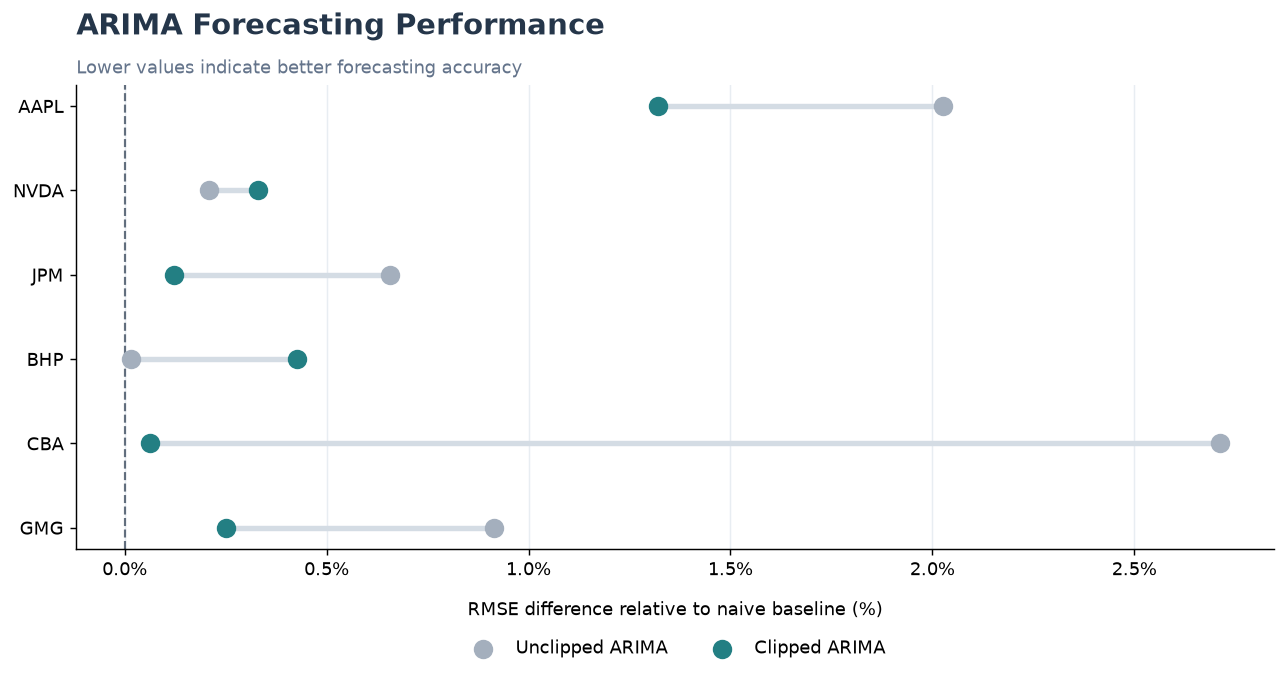

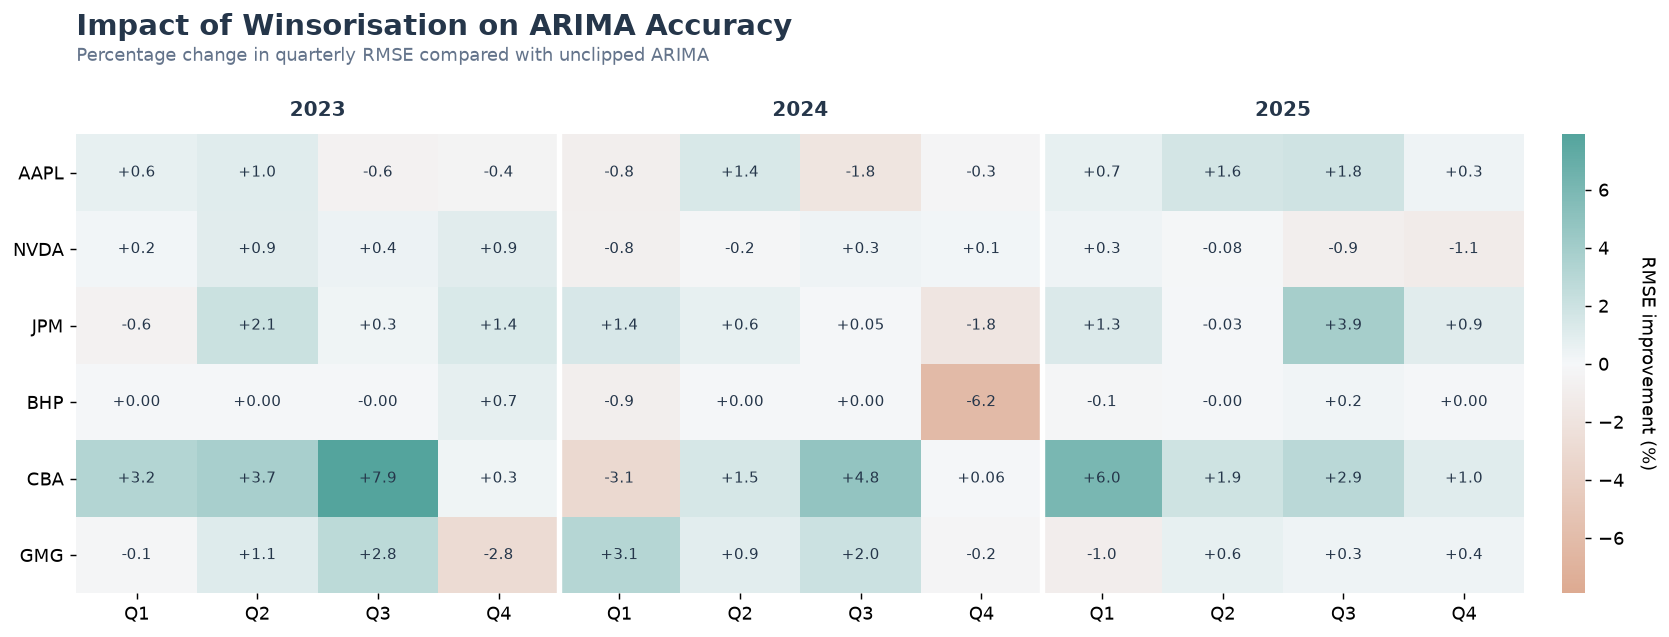

In [63]:

# ARIMA visualisations

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import FuncFormatter

# Formatting across both figures
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 130,
    "savefig.dpi": 300
})

stocks = ["AAPL", "NVDA", "JPM", "BHP", "CBA", "GMG"]

navy = "#25364A"
teal = "#237F83"
grey = "#A4AFBD"
grid_color = "#E8EDF2"


# --------------------------------------------------
# Figure 1: ARIMA performance relative to naive
# --------------------------------------------------

plot_data = comparison_summary.set_index("Stock").loc[stocks]

unclipped_diff = 100 * (
    plot_data["Unclipped_RMSE"] - plot_data["Naive_RMSE"]
) / plot_data["Naive_RMSE"]

clipped_diff = 100 * (
    plot_data["Clipped_RMSE"] - plot_data["Naive_RMSE"]
) / plot_data["Naive_RMSE"]

fig, ax = plt.subplots(figsize=(10, 5.5))

y = np.arange(len(stocks))

# Connecting both modelling approaches for each stock
ax.hlines(
    y,
    np.minimum(unclipped_diff, clipped_diff),
    np.maximum(unclipped_diff, clipped_diff),
    color="#D4DCE4",
    linewidth=3,
    zorder=1
)

# Plotting unclipped and clipped results
ax.scatter(
    unclipped_diff, y,
    s=95,
    color=grey,
    label="Unclipped ARIMA",
    zorder=3
)

ax.scatter(
    clipped_diff, y,
    s=95,
    color=teal,
    label="Clipped ARIMA",
    zorder=4
)

# Identifying the naive persistence benchmark
ax.axvline(
    0,
    color=navy,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7
)

ax.set_yticks(y)
ax.set_yticklabels(stocks, fontweight="medium")
ax.invert_yaxis()

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, pos: f"{value:.1f}%")
)

ax.set_xlabel(
    "RMSE difference relative to naive baseline (%)",
    labelpad=12
)

ax.set_title(
    "ARIMA Forecasting Performance",
    fontsize=16,
    fontweight="bold",
    color=navy,
    loc="left",
    pad=28
)

ax.text(
    0, 1.025,
    "Lower values indicate better forecasting accuracy",
    transform=ax.transAxes,
    fontsize=10,
    color="#64748B"
)

ax.grid(axis="x", color=grid_color, linewidth=0.8)
ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.27),
    ncol=2
)

fig.tight_layout()

fig.savefig(
    results_dir / "ARIMA_RMSE_Baseline_Comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# --------------------------------------------------
# Figure 2: Quarterly improvement from winsorisation
# --------------------------------------------------

quarterly_plot = quarterly_comparison.copy()

# Positive values indicate lower RMSE after clipping
quarterly_plot["Improvement_Percent"] = 100 * (
    quarterly_plot["Unclipped_RMSE"] -
    quarterly_plot["Clipped_RMSE"]
) / quarterly_plot["Unclipped_RMSE"]

matrix = quarterly_plot.pivot(
    index="Stock",
    columns="Fold",
    values="Improvement_Percent"
).reindex(index=stocks, columns=range(1, 13))

assert matrix.notna().all().all()

values = matrix.to_numpy()

# Muted diverging palette: orange = worse, teal = better
cmap = LinearSegmentedColormap.from_list(
    "arima_improvement",
    ["#DDAA91", "#F5F7F9", "#54A49D"]
)

limit = max(0.1, float(np.abs(values).max()))

fig, ax = plt.subplots(figsize=(13, 5))

heatmap = ax.imshow(
    values,
    cmap=cmap,
    norm=TwoSlopeNorm(
        vmin=-limit,
        vcenter=0,
        vmax=limit
    ),
    aspect="auto"
)

# Displaying quarter labels
ax.set_xticks(np.arange(12))
ax.set_xticklabels(
    ["Q1", "Q2", "Q3", "Q4"] * 3
)

ax.set_yticks(np.arange(len(stocks)))
ax.set_yticklabels(stocks, fontweight="medium")

# Group quarters into calendar years
for position, year in [
    (1.5, "2023"),
    (5.5, "2024"),
    (9.5, "2025")
]:
    ax.text(
        position, 1.04, year,
        transform=ax.get_xaxis_transform(),
        ha="center",
        fontsize=11,
        fontweight="bold",
        color=navy
    )

# Separating calendar years visually
ax.axvline(3.5, color="white", linewidth=3)
ax.axvline(7.5, color="white", linewidth=3)

# Labelling each cell with its actual percentage improvement
for i in range(len(stocks)):
    for j in range(12):
        value = values[i, j]

        label = (
            f"{value:+.2f}"
            if abs(value) < 0.1
            else f"{value:+.1f}"
        )

        ax.text(
            j, i, label,
            ha="center",
            va="center",
            fontsize=8.5,
            color=navy
        )

# Removing surrounding borders
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    "Impact of Winsorisation on ARIMA Accuracy",
    fontsize=16,
    fontweight="bold",
    color=navy,
    loc="left",
    pad=55
)

ax.text(
    0, 1.16,
    "Percentage change in quarterly RMSE compared with unclipped ARIMA",
    transform=ax.transAxes,
    fontsize=10,
    color="#64748B"
)

# Explaining the improvement scale
colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.025,
    pad=0.025
)

colorbar.set_label(
    "RMSE improvement (%)",
    rotation=270,
    labelpad=18
)

colorbar.outline.set_visible(False)

fig.tight_layout()

fig.savefig(
    results_dir / "ARIMA_Quarterly_Clipping_Improvement.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


## Conclusion

For this study, the effectiveness of the ARIMA forecasts was assessed on six stocks by performing 12 quarterly walk-forward folds between 2023 and 2025. The study involved the use of two sets of models: unclipped log-price models and winsorised return-based models, which resulted in 4,526 daily forecasts per method. Clipped-return approach performed better than others for 48 out of 72 quarterly folds and enhanced forecasting accuracy of the four stocks out of six. However, naive persistence approach had the lowest RMSE values for all stocks, indicating that there is little room to outperform it consistently. Residual analyses revealed further limitations. While all models converged, only 32 out of 72 unclipped models passed both Ljung–Box tests, indicating that not all temporal patterns were adequately captured.

In conclusion, while clipped return modelling may prove useful for enhancing ARIMA forecasts in some cases, its effect is not uniform across all stocks considered. Since the two approaches utilise different model settings, one cannot explain the observed difference in the performance of the models solely by means of winsorisation. The results obtained form the statistical baseline for the comparison of predictive abilities of LSTM and CNN-LSTM models.